# Thrombectomy use and variation in transfer for thrombectomy

This notebook describes the use of thrombectomy (mechanical thrombectomy, MT) using SAMueL-3 SSNAP data, with a focus on patients who first attend a hospital without thrombectomy and must be transferred for it. It combines descriptive statistics with a machine learning model (XGBoost) of which patients receive thrombectomy.

**Aims**

1. Describe how often patients with ischaemic stroke and NIHSS > 10 receive thrombectomy, by the type of hospital first attended and by thrombolysis.
2. Compare patients treated with thrombectomy after transfer with those treated directly: time from arrival to thrombectomy, and patient characteristics.
3. Describe how much non-thrombectomy centres vary in thrombolysis and in transfer for thrombectomy, and whether variation in thrombolysis explains variation in transfer.
4. Establish whether stroke teams differ in *how many* patients they send for thrombectomy, *which* patients they send, or both.
5. Examine how teams' thrombectomy rates relate to the thrombectomy unit they transfer to, and to that unit's rate for its own patients.

**Population**

Stroke admissions in SSNAP in 2024–2025 (set by `min_year` and `max_year`). Most analyses use patients with **ischaemic stroke and NIHSS > 10** (`data_filtered`, 27,147 patients), as those most likely to be eligible for thrombectomy. Subsets used in particular sections:
- **Thrombectomy within 12 hours:** patients who received thrombectomy within 12 hours of arrival (5,287), for the time and patient characteristic comparisons.
- **Non-thrombectomy centres:** patients who first attended one of 87 non-thrombectomy centres (18,296 with ischaemic stroke and NIHSS > 10). The centre-level thrombolysis and transfer rates also use all admissions to these centres (110,090).
- **Thrombectomy units:** patients of non-thrombectomy centres with a known thrombectomy unit (`MT_transfer_unit`; 18,189 patients, 86 teams, 21 units), compared with patients who first attended those units.

For patients who first attend a non-thrombectomy centre, receiving thrombectomy is used as the measure of transfer for thrombectomy (96% of these thrombectomies had a transfer recorded).

**Contents**

1. **Load data and overall thrombectomy rates:** loads the data, restricts it to the target years, ischaemic stroke and NIHSS > 10, and compares thrombectomy rates by type of hospital first attended and by thrombolysis.
2. **Patients receiving thrombectomy within 12 hours of arrival:** time from arrival to thrombectomy, and patient characteristics (standardised mean differences), by whether patients first attended a thrombectomy centre.
3. **Thrombolysis and transfer for thrombectomy by non-thrombectomy centre:** variation between centres, and whether thrombolysis explains variation in transfer.
4. **Do stroke teams differ in which patients they select for thrombectomy?** An XGBoost model (tuned with Optuna, explained with SHAP) predicting thrombectomy for the same patients at every team.
5. **Thrombectomy units and variation between referring teams:** teams' rates grouped by thrombectomy unit, and their relationship with the unit's rate for its own patients.
6. **Conclusions.**

Each code cell has a description of its method above it and a commentary on its results below it. Options (`use_anon_teams`, `retune_model`) are set in the data-loading cell. Tables and figures are saved to `./output/`.

## Load data and overall thrombectomy rates

**What this cell does:** Imports the libraries used in this notebook: matplotlib for plotting, NumPy for numerical work and pandas for data handling.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

**What this cell does:** Sets two options: `use_anon_teams` (described below) and `retune_model`, which controls whether the XGBoost model further down is re-tuned (True, about 5 minutes) or uses the previously saved hyperparameters (False, the default). It then loads the cleaned SAMueL-3 SSNAP data: with anonymised stroke teams (`cleaned_data_anon_teams.csv`) when `use_anon_teams` is True (as now), otherwise with real team names (`cleaned_data.csv`). Keeps admissions from `min_year` to `max_year` inclusive (currently 2024–2025) as `data_filtered`, and shows the proportion of all these admissions who received thrombectomy.

In [2]:
# Settings
# use_anon_teams: load data with anonymised stroke team names (True) or real names (False)
# retune_model: re-tune the XGBoost hyperparameters with Optuna (~5 min) and save them to
#   output/xgb_tuning.json (True), or load the previously saved hyperparameters (False)
use_anon_teams = True
retune_model = False

if use_anon_teams:
    all_data = pd.read_csv("../data/sam3/cleaned_data_anon_teams.csv", low_memory=False)
else:
    all_data = pd.read_csv("../data/sam3/cleaned_data.csv", low_memory=False)

# Select years to include (inclusive)
min_year = 2024
max_year = 2025

# Get data for selected years
mask = (all_data['year'] >= min_year) & (all_data['year'] <= max_year)
data_filtered = all_data[mask]

# Get the avergae thrombectomy of all patients
data_filtered['thrombectomy'].mean()


np.float64(0.04623897895562257)

**Results:** 4.6% of all stroke admissions in the selected years received thrombectomy.

**What this cell does:** Restricts `data_filtered` to ischaemic stroke (`infarction` = 1) and recalculates the proportion receiving thrombectomy.

In [3]:
# Limit to infarction == 1
data_filtered = data_filtered[data_filtered['infarction'] == 1]
data_filtered['thrombectomy'].mean()

np.float64(0.0533426491137751)

**Results:** 5.3% of ischaemic stroke admissions received thrombectomy.

**What this cell does:** Restricts to more severe strokes (NIHSS `stroke_severity` > 10) and shows the proportion of these patients receiving thrombectomy. This is the population used for the thrombectomy rates below.

In [4]:
# Limit to stroke_severity > 10
data_filtered = data_filtered[data_filtered['stroke_severity'] > 10]
data_filtered['thrombectomy'].mean()

np.float64(0.20466349872914133)

**Results:** 20.5% of ischaemic stroke patients with NIHSS > 10 received thrombectomy.

**What this cell does:** Calculates the proportion of patients receiving thrombectomy, split by whether they first attended a thrombectomy centre (`thrombectomy_centre` = 1) or not (0).

In [5]:
# Get proportion thrombectomy by thrombectomy_centre
proportion_thrombectomy = data_filtered.groupby('thrombectomy_centre')['thrombectomy'].mean()
proportion_thrombectomy


thrombectomy_centre
0    0.177634
1    0.260536
Name: thrombectomy, dtype: float64

**Results:** Patients who first attended a thrombectomy centre were more likely to receive thrombectomy: 26.1% compared with 17.8% of those who first attended a non-thrombectomy centre.

**What this cell does:** Counts patients, and the proportion receiving thrombectomy, split by first-attended centre type *and* by whether they also received thrombolysis. The index is renamed and reset to give a flat, readable table.

In [6]:
df_split = data_filtered.groupby(
    ["thrombectomy_centre", "thrombolysis"]
).agg({"thrombectomy": ["mean", "count"]})

# Make df_split index more readable
df_split.index = df_split.index.set_names(["Thrombectomy Centre", "Thrombolysis"])

# Unmerge index
df_split = df_split.reset_index()

df_split


Thrombectomy Centre Thrombolysis thrombectomy       
                                           mean  count
0                   0            0     0.122092  12507
1                   0            1     0.297633   5789
2                   1            0     0.203890   6273
3                   1            1     0.398371   2578

**Results:** Proportion receiving thrombectomy (and number of patients) by first-attended centre type and thrombolysis:

| First attended | No thrombolysis | Thrombolysis |
|---|---|---|
| Non-thrombectomy centre | 12.2% (n = 12,507) | 29.8% (n = 5,789) |
| Thrombectomy centre | 20.4% (n = 6,273) | 39.8% (n = 2,578) |

Thrombectomy rates are higher at thrombectomy centres both with and without thrombolysis. Within each type of centre, patients who received thrombolysis were about two to two-and-a-half times as likely to also receive thrombectomy. This probably reflects patients arriving earlier and being more suitable for reperfusion treatment, not an effect of thrombolysis itself. The proportion receiving thrombolysis was similar: 31.6% at non-thrombectomy centres and 29.1% at thrombectomy centres. In total, 27,147 patients have a known first-attended centre type.

## Patients receiving thrombectomy within 12 hours of arrival

**What this cell does:** Keeps only patients whose arrival-to-thrombectomy time is 12 hours (720 min) or less, and stores them as `data_filtered_12hr` (`data_filtered` itself is unchanged).

**Note:** patients who did not have thrombectomy have no arrival-to-thrombectomy time (NaN), and NaN fails the `<= 720` test, so this filter also removes every non-thrombectomy patient. `data_filtered_12hr` therefore contains **only thrombectomy patients treated within 12 hours of arrival**, and the cells below use it.

In [7]:
# Clip arrival-to-thrombectomy times at 12 hours
mask = data_filtered['arrival_to_thrombectomy_time'] <= 720
data_filtered_12hr = data_filtered[mask]

**Results:** No output is shown. After this filter, 5,287 thrombectomy patients with a known first-attended centre type remain: 3,073 who first attended a non-thrombectomy centre and 2,214 who first attended a thrombectomy centre (see the counts below).

**What this cell does:** Summarises arrival-to-thrombectomy time (minutes from arrival at the first hospital to thrombectomy) for patients who first attended a non-thrombectomy centre (0) versus a thrombectomy centre (1).

In [8]:
data_filtered_12hr.groupby(
    ["thrombectomy_centre"])['arrival_to_thrombectomy_time'].describe().T

thrombectomy_centre,0,1
count,3073.000000,2214.000000
mean,246.262935,150.522132
std,99.859412,92.896233
min,0.000000,0.000000
25%,181.000000,97.000000
50%,221.000000,127.000000
75%,284.000000,174.000000
max,720.000000,720.000000


**Results:** Patients who first attended a non-thrombectomy centre waited much longer from arrival to thrombectomy: median 221 min (IQR 181–284) versus 127 min (IQR 97–174) at thrombectomy centres, about 1.5 hours longer. Mean times are 246 versus 151 min. This difference is consistent with the time needed for inter-hospital transfer. The maximum of 720 min in both groups reflects the 12-hour limit applied earlier.

**What this cell does:** Summarises arrival-to-thrombectomy time split by both first-attended centre type and thrombolysis, to see whether thrombolysis is associated with a different time to thrombectomy.

In [9]:
data_filtered_12hr.groupby(
    ["thrombectomy_centre", "thrombolysis"])['arrival_to_thrombectomy_time'].describe().T

thrombectomy_centre            0                         1            
thrombolysis                   0            1            0           1
count                1428.000000  1645.000000  1236.000000  978.000000
mean                  258.436275   235.695441   154.633495  145.326176
std                   105.855315    93.096033   100.637744   81.830560
min                    90.000000     0.000000     0.000000    0.000000
25%                   188.000000   177.000000    97.000000   97.000000
50%                   231.000000   214.000000   127.000000  126.500000
75%                   303.000000   270.000000   176.250000  167.750000
max                   720.000000   718.000000   709.000000  720.000000

**Results:** Thrombolysis makes little difference to time to thrombectomy within each centre type. Non-thrombectomy centre: median 231 min without thrombolysis versus 214 min with it. Thrombectomy centre: 127 versus 126.5 min. The type of centre first attended is what drives the time difference.

### Characteristics of thrombectomy patients by first-attended centre

Compare patients who received thrombectomy, split by whether they first attended a thrombectomy centre (`thrombectomy_centre` = 1) or a non-thrombectomy centre (`thrombectomy_centre` = 0, mostly transferred for thrombectomy).

Note: these comparisons use `data_filtered_12hr`, the 12-hour `arrival_to_thrombectomy_time` subset created above, which contains only thrombectomy patients (non-thrombectomy patients have no time recorded).

**What this cell does:** Selects thrombectomy patients with a known first-attended centre type (`thrombectomy_patients`). Converts the categorical fields (ethnicity, prior mRS and discharge mRS) to one 0/1 column per level so each level can be compared as a proportion; missing discharge mRS stays missing rather than becoming 0. Adds a readable group label (`first_centre`) and counts patients in each group.

In [10]:
from scipy import stats

# Thrombectomy patients only, split by whether first attended a thrombectomy centre
thrombectomy_patients = data_filtered_12hr[
    (data_filtered_12hr['thrombectomy'] == 1) & (data_filtered_12hr['thrombectomy_centre'].notna())
].copy()

# One-hot encode categorical fields so each level can be compared as a proportion
thrombectomy_patients = pd.concat([
    thrombectomy_patients,
    pd.get_dummies(thrombectomy_patients['ethnicity'], prefix='ethnicity', dtype=float),
    pd.get_dummies(thrombectomy_patients['prior_disability'], prefix='prior_mrs', dtype=float),
    # Keep missing discharge mRS as missing (rather than 0 in every dummy column)
    pd.get_dummies(thrombectomy_patients['discharge_disability'], prefix='discharge_mrs', dtype=float)
      .where(thrombectomy_patients['discharge_disability'].notna()),
], axis=1)

group_labels = {0: 'Non-thrombectomy centre', 1: 'Thrombectomy centre'}
thrombectomy_patients['first_centre'] = (
    thrombectomy_patients['thrombectomy_centre'].astype(int).map(group_labels))

thrombectomy_patients['first_centre'].value_counts()

first_centre
Non-thrombectomy centre    3073
Thrombectomy centre        2214
Name: count, dtype: int64

**Results:** 5,287 thrombectomy patients: 3,073 (58%) first attended a non-thrombectomy centre and 2,214 (42%) first attended a thrombectomy centre.

### Standardised mean difference (SMD)

The SMD measures how different the two groups are on each characteristic, in units of standard deviation, so that variables on different scales can be compared. It is calculated by \`standardised_mean_difference(x1, x0)\`, where \`x1\` = patients who first attended a thrombectomy centre (\`thrombectomy_centre\` = 1) and \`x0\` = patients who first attended a non-thrombectomy centre (\`thrombectomy_centre\` = 0). Missing values are dropped separately for each variable.

The same formula is used for all variables:

$$
\text{SMD} = \frac{\bar{x}_1 - \bar{x}_0}{\sqrt{\dfrac{s_1^2 + s_0^2}{2}}}
$$

where $\bar{x}$ is the group mean and $s^2$ is the group sample variance (pandas \`.var()\`, i.e. dividing by $n - 1$).

**Continuous variables** (e.g. age, NIHSS, times): $\bar{x}$ and $s^2$ are the ordinary mean and variance of the values in each group. Note that the table reports median [IQR] for these variables, but the SMD is based on **means**, so the SMD can differ in size (or occasionally in direction) from the difference in medians. Banded or ordinal variables (age bands, prior mRS) are treated as numbers.

**Binary variables** (coded 0/1): the mean is the proportion $p$ with the characteristic, and the variance is $p(1 - p)$ (multiplied by $n/(n-1)$, which is negligible here). The formula therefore becomes the standard SMD for proportions:

$$
\text{SMD} = \frac{p_1 - p_0}{\sqrt{\dfrac{p_1(1 - p_1) + p_0(1 - p_0)}{2}}}
$$

For example, Asian ethnicity: $p_1 = 96/2214 = 0.043$ and $p_0 = 119/3073 = 0.039$, so SMD $= 0.0046 / 0.198 = 0.02$.

**Interpretation**
* Positive SMD: higher mean (or proportion) in thrombectomy centres; negative SMD: higher in non-thrombectomy centres.
* If both groups have zero variance, the SMD is not defined (returned as NaN).
* $|\text{SMD}| > 0.1$ is commonly taken to indicate a meaningful imbalance. Unlike the p-value, the SMD does not depend on sample size.

**What this cell does:** Builds the comparison table (`comparison`). For each characteristic it gives, for each group: % (n) for binary variables or median [IQR] for continuous variables, the number of patients with data, the SMD (see above), and a p-value (chi-square test for binary variables, Mann–Whitney U test for continuous variables).

In [11]:
# Characteristics to compare: (variable, label, type) where type is 'binary' or 'continuous'
ethnicity_cols = sorted(c for c in thrombectomy_patients.columns if c.startswith('ethnicity_'))
prior_mrs_cols = sorted(c for c in thrombectomy_patients.columns if c.startswith('prior_mrs_'))
discharge_mrs_cols = sorted(c for c in thrombectomy_patients.columns if c.startswith('discharge_mrs_'))

variables = (
    [('age', 'Age (years, banded)', 'continuous'),
     ('male', 'Male', 'binary')]
    + [(c, f"Ethnicity: {c.replace('ethnicity_', '')}", 'binary') for c in ethnicity_cols]
    + [('stroke_severity', 'NIHSS on arrival', 'continuous'),
       ('lvo', 'Large vessel occlusion (where recorded)', 'binary'),
       ('prior_disability', 'Prior mRS', 'continuous')]
    + [(c, f"Prior mRS {c.replace('prior_mrs_', '')}", 'binary') for c in prior_mrs_cols]
    + [('congestive_heart_failure', 'Congestive heart failure', 'binary'),
       ('hypertension', 'Hypertension', 'binary'),
       ('atrial_fibrillation', 'Atrial fibrillation', 'binary'),
       ('diabetes', 'Diabetes', 'binary'),
       ('prior_stroke_tia', 'Prior stroke/TIA', 'binary'),
       ('afib_anticoagulant', 'AF on anticoagulant', 'binary'),
       ('onset_known', 'Onset time known', 'binary'),
       ('precise_onset_known', 'Precise onset known', 'binary'),
       ('onset_during_sleep', 'Onset during sleep', 'binary'),
       ('arrive_by_ambulance', 'Arrived by ambulance', 'binary'),
       ('onset_to_arrival_time', 'Onset to arrival (min)', 'continuous'),
       ('arrival_to_scan_time', 'Arrival to scan (min)', 'continuous'),
       ('perfusion_imaging_used', 'Perfusion imaging used', 'binary'),
       ('aspects_score', 'ASPECTS (where recorded)', 'continuous'),
       ('thrombolysis', 'Thrombolysis', 'binary'),
       ('arrival_to_thrombolysis_time', 'Arrival to thrombolysis (min)', 'continuous'),
       ('arrival_to_thrombectomy_referral_time', 'Arrival to thrombectomy referral (min)', 'continuous'),
       ('arrival_to_thrombectomy_time', 'First arrival to thrombectomy (min)', 'continuous'),
       ('onset_to_thrombectomy_time', 'Onset to thrombectomy (min)', 'continuous'),
       ('discharge_disability', 'Discharge mRS', 'continuous')]
    + [(c, f"Discharge mRS {c.replace('discharge_mrs_', '').replace('.0', '')}", 'binary')
       for c in discharge_mrs_cols]
    + [('death', 'Died before discharge', 'binary'),
       ('length_of_stay', 'Length of stay (days)', 'continuous')]
)


def standardised_mean_difference(x1, x0):
    """SMD (thrombectomy centre minus non-thrombectomy centre) using pooled SD."""
    pooled_sd = np.sqrt((x1.var() + x0.var()) / 2)
    return (x1.mean() - x0.mean()) / pooled_sd if pooled_sd > 0 else np.nan


rows = []
for var, label, kind in variables:
    x0 = thrombectomy_patients.loc[thrombectomy_patients['thrombectomy_centre'] == 0, var].dropna()
    x1 = thrombectomy_patients.loc[thrombectomy_patients['thrombectomy_centre'] == 1, var].dropna()
    if kind == 'binary':
        summary0 = f"{x0.mean() * 100:.1f}% ({int(x0.sum())})"
        summary1 = f"{x1.mean() * 100:.1f}% ({int(x1.sum())})"
        table = [[x0.sum(), len(x0) - x0.sum()], [x1.sum(), len(x1) - x1.sum()]]
        p = stats.chi2_contingency(table)[1] if min(x0.sum() + x1.sum(), len(x0) + len(x1) - x0.sum() - x1.sum()) > 0 else np.nan
    else:
        summary0 = f"{x0.median():g} [{x0.quantile(0.25):g}-{x0.quantile(0.75):g}]"
        summary1 = f"{x1.median():g} [{x1.quantile(0.25):g}-{x1.quantile(0.75):g}]"
        p = stats.mannwhitneyu(x0, x1).pvalue if len(x0) and len(x1) else np.nan
    rows.append({
        'Characteristic': label,
        'Non-thrombectomy centre': summary0,
        'Thrombectomy centre': summary1,
        'n (non-TC / TC)': f"{len(x0)} / {len(x1)}",
        'SMD': standardised_mean_difference(x1, x0),
        'p': p,
    })

comparison = pd.DataFrame(rows).set_index('Characteristic')
comparison['SMD'] = comparison['SMD'].round(2)
comparison['p'] = comparison['p'].map(lambda v: '<0.001' if v < 0.001 else f"{v:.3f}")

print('Binary: % (n). Continuous: median [IQR]. SMD = Standardised Mean Difference.')
pd.set_option('display.max_rows', 200)
comparison

Binary: % (n). Continuous: median [IQR]. SMD = Standardised Mean Difference.


,Non-thrombectomy centre,Thrombectomy centre,n (non-TC / TC),SMD,p
Characteristic,,,,,
"Age (years, banded)",72.5 [62.5-82.5],72.5 [62.5-82.5],3073 / 2214,-0.09,0.003
Male,54.6% (1679),53.9% (1192),3073 / 2213,-0.02,0.597
Ethnicity: Asian,3.9% (119),4.3% (96),3073 / 2214,0.02,0.440
Ethnicity: Black,1.2% (37),5.5% (121),3073 / 2214,0.24,<0.001
Ethnicity: Mixed,0.2% (5),1.4% (32),3073 / 2214,0.14,<0.001
Ethnicity: Other/NK,12.1% (372),18.8% (417),3073 / 2214,0.19,<0.001
Ethnicity: White,82.7% (2540),69.9% (1548),3073 / 2214,-0.30,<0.001
NIHSS on arrival,18 [15-21],19 [15-22],3073 / 2214,0.11,<0.001
Large vessel occlusion (where recorded),88.9% (1771),88.4% (1247),1992 / 1410,-0.01,0.713


**Results:** The two groups are similar on many clinical characteristics: large vessel occlusion, comorbidities (hypertension, AF, diabetes, prior stroke/TIA, congestive heart failure) and arrival-to-scan time all have |SMD| < 0.1. NIHSS is slightly higher at thrombectomy centres (median 19 versus 18, SMD 0.11).

The main differences (|SMD| ≥ 0.1; thrombectomy centre first) are:
* **Timings:** first arrival to thrombectomy, median 127 versus 221 min (SMD −0.99, by far the largest difference); arrival to thrombectomy referral, 51 versus 57 min (−0.21, but recorded for only 286 thrombectomy-centre patients); onset to thrombectomy, 275 versus 368.5 min (−0.14); arrival to thrombolysis, 44 versus 48 min (−0.12).
* **Ethnicity:** patients first attending a thrombectomy centre are less often White (69.9% versus 82.7%, SMD −0.30) and more often Black (5.5% versus 1.2%, 0.24), Mixed (1.4% versus 0.2%, 0.14) or Other/not known (18.8% versus 12.1%, 0.19).
* **Prior disability:** slightly higher at thrombectomy centres (prior mRS SMD 0.19; prior mRS 0: 53.5% versus 62.2%, −0.18; prior mRS 2: 13.6% versus 9.3%, 0.14).
* **Imaging and treatment:** perfusion imaging (12.2% versus 20.1%, SMD −0.22) and thrombolysis (44.2% versus 53.5%, SMD −0.19) are both less common at thrombectomy centres.

Prior mRS 3, precise onset known, age and congestive heart failure sit just under the threshold (|SMD| 0.09–0.10).

Unadjusted outcomes are similar: median discharge mRS 3 in both groups, and in-hospital death 14.0% versus 14.4% (SMD −0.01). These are crude comparisons and should not be read as the effect of first-attended centre type.

Many p-values are < 0.001 even where the SMD is small, because the sample is large. Use the SMD to judge whether a difference is meaningful.

**What this cell does:** Plots the SMD for every characteristic as a horizontal bar chart, sorted so the largest imbalances are at the top. Bars beyond the ±0.1 threshold (dashed lines) are red. The figure is saved to `output/thrombectomy_by_first_centre_smd.png`.

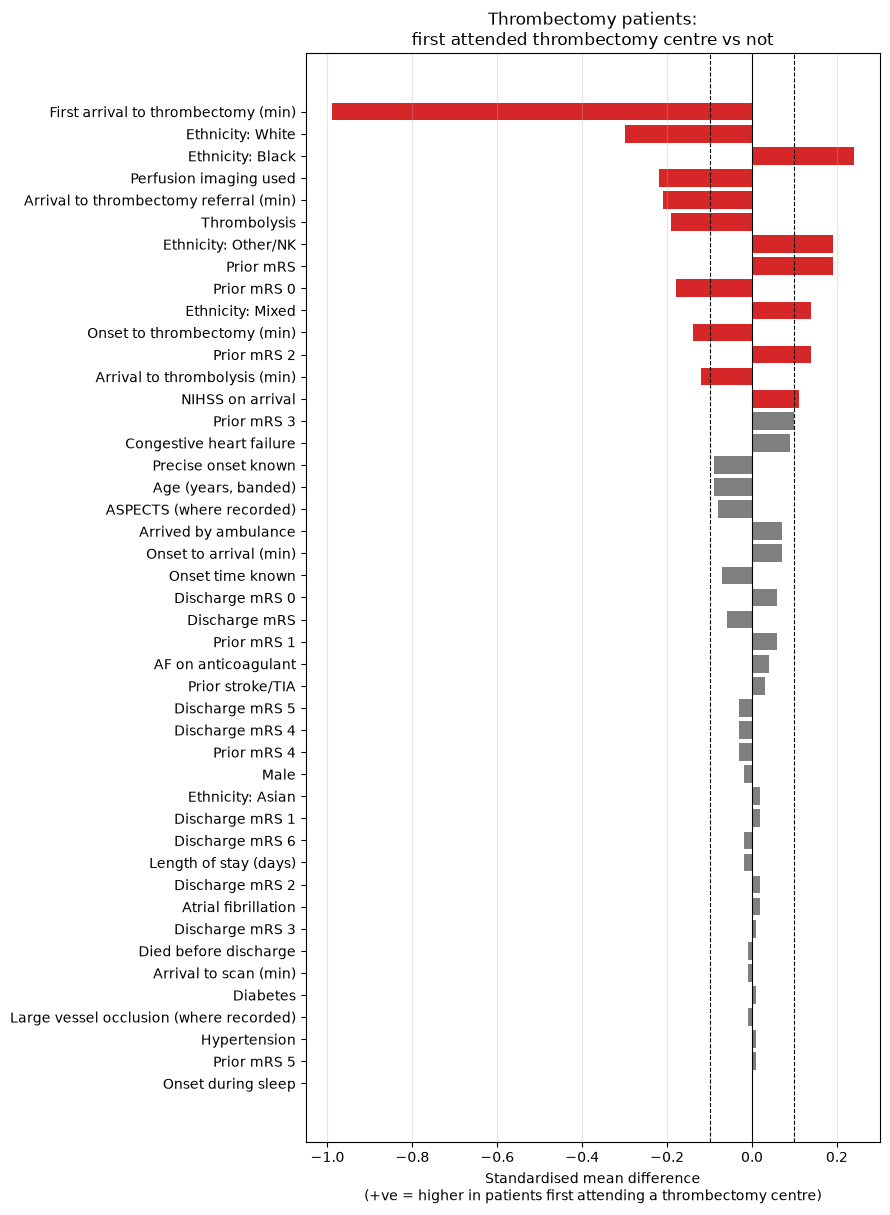

In [12]:
# Plot standardised mean differences (|SMD| > 0.1 is a common threshold for a meaningful imbalance)
# Sort by |SMD| ascending so the largest imbalance appears at the top of the barh chart
plot_data = comparison['SMD'].dropna()
plot_data = plot_data.reindex(plot_data.abs().sort_values().index)
colours = np.where(plot_data.abs() > 0.1, 'tab:red', 'tab:grey')

fig, ax = plt.subplots(figsize=(9, 0.25 * len(plot_data) + 1))
ax.barh(plot_data.index, plot_data.values, color=colours)
for x in (-0.1, 0.1):
    ax.axvline(x, color='k', linestyle='--', linewidth=0.8)
ax.axvline(0, color='k', linewidth=0.8)
ax.set_xlabel('Standardised mean difference\n(+ve = higher in patients first attending a thrombectomy centre)')
ax.set_title('Thrombectomy patients:\nfirst attended thrombectomy centre vs not')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('output/thrombectomy_by_first_centre_smd.png', dpi=300, bbox_inches='tight')
plt.show()

**Results:** 14 characteristics exceed the ±0.1 threshold. In order of size: first arrival to thrombectomy time (−0.99, far larger than any other), White ethnicity (−0.30), Black ethnicity (0.24), perfusion imaging (−0.22), arrival to thrombectomy referral time (−0.21), prior mRS (0.19), thrombolysis (−0.19), Other/not known ethnicity (0.19), prior mRS 0 (−0.18), Mixed ethnicity (0.14), onset to thrombectomy time (−0.14), prior mRS 2 (0.14), arrival to thrombolysis time (−0.12) and NIHSS (0.11). Prior mRS 3, precise onset known, age and congestive heart failure are just inside the threshold. All other characteristics are within ±0.1.

## Thrombolysis and transfer for thrombectomy by non-thrombectomy centre

Compare the non-thrombectomy centres (`thrombectomy_centre` = 0) on how often they give thrombolysis and how often they transfer patients out for thrombectomy. Each rate is calculated for all stroke admissions in the target years (2024–2025, set by `min_year` and `max_year`), and for ischaemic stroke with NIHSS > 10, the patients most likely to be eligible for thrombectomy. The transfer rate is also calculated for the ischaemic NIHSS > 10 patients who were thrombolysed.

"Transferred" means `transfer_used` = 1 (transferred to another hospital for thrombectomy). Across these centres, 4,024 of the 5,025 transferred patients (80%) went on to have thrombectomy, and 173 patients had thrombectomy recorded without a transfer.

**What this cell does:** Starts again from `all_data`, because `data_filtered` has already been restricted to ischaemic stroke with NIHSS > 10. Keeps the target years and the non-thrombectomy centres, then calculates for each stroke team the number of patients, % thrombolysed and % transferred for thrombectomy: first for all patients, then for ischaemic stroke with NIHSS > 10. It adds the number of ischaemic NIHSS > 10 patients who were thrombolysed and the % of them transferred (their % thrombolysed is 100% by definition, so it is dropped). Teams are sorted by the ischaemic NIHSS > 10 transfer rate, highest first, and the table is saved to `output/non_thrombectomy_centre_rates.csv`.

In [13]:
# Start again from all_data: data_filtered has already been restricted above
year_mask = (all_data['year'] >= min_year) & (all_data['year'] <= max_year)
non_tc_all = all_data[year_mask & (all_data['thrombectomy_centre'] == 0)]
non_tc_severe = non_tc_all[
    (non_tc_all['infarction'] == 1) & (non_tc_all['stroke_severity'] > 10)
]
# Ischaemic NIHSS > 10 patients who were also thrombolysed
non_tc_severe_ivt = non_tc_severe[non_tc_severe['thrombolysis'] == 1]

def centre_rates(df, label):
    """Patients, % thrombolysed and % transferred for thrombectomy per stroke team."""
    rates = df.groupby('stroke_team').agg(
        n=('thrombolysis', 'size'),
        thrombolysed=('thrombolysis', 'mean'),
        transferred=('transfer_used', 'mean'),
    )
    rates[['thrombolysed', 'transferred']] *= 100
    rates.columns = [
        f'Patients ({label})',
        f'Thrombolysed % ({label})',
        f'Transferred % ({label})',
    ]
    return rates

# For the thrombolysed subset only the transfer rate is informative (all are thrombolysed)
ivt_rates = centre_rates(non_tc_severe_ivt, 'ischaemic NIHSS>10 thrombolysed').drop(
    columns='Thrombolysed % (ischaemic NIHSS>10 thrombolysed)')
non_tc_rates = (
    centre_rates(non_tc_all, 'all')
    .join(centre_rates(non_tc_severe, 'ischaemic NIHSS>10'))
    .join(ivt_rates)
)
non_tc_rates = non_tc_rates.sort_values(
    'Transferred % (ischaemic NIHSS>10)', ascending=False)
non_tc_rates.to_csv('output/non_thrombectomy_centre_rates.csv')

pd.set_option('display.max_rows', 120)
non_tc_rates.round(1)

,Patients (all),Thrombolysed % (all),Transferred % (all),Patients (ischaemic NIHSS>10),Thrombolysed % (ischaemic NIHSS>10),Transferred % (ischaemic NIHSS>10),Patients (ischaemic NIHSS>10 thrombolysed),Transferred % (ischaemic NIHSS>10 thrombolysed)
stroke_team,,,,,,,,
MTU,987,9.0,5.3,98,27.6,37.8,27,37.0
EUB,1134,23.5,7.7,194,55.2,36.6,107,43.9
LSO,1215,9.6,9.1,216,25.5,36.6,55,45.5
AGD,1684,17.5,7.2,251,43.0,35.9,108,52.8
ORC,1103,14.4,9.8,225,26.2,33.3,59,44.1
FNY,1710,13.5,8.1,280,37.9,33.2,106,56.6
YZR,1646,6.1,6.1,180,19.4,32.8,35,42.9
YWT,1454,18.2,7.1,229,43.7,32.3,100,48.0
FQE,1210,16.2,4.5,140,42.9,31.4,60,45.0


**Results:** There are 87 non-thrombectomy centres, with 110,090 admissions in total, 18,296 with ischaemic stroke and NIHSS > 10, and 5,789 of those thrombolysed.

For ischaemic stroke with NIHSS > 10, the highest transfer rates are at MTU (37.8%), EUB and LSO (both 36.6%) and AGD (35.9%). The lowest are at QVM (0.6%), GAJ (5.5%), STK (7.6%) and WVO (7.7%).

QVM's 0.6% should be checked. Of its ischaemic NIHSS > 10 patients, 6.2% have thrombectomy recorded, so transfers may be under-recorded in `transfer_used` there. Some centres are small (six have fewer than 70 ischaemic NIHSS > 10 patients, the smallest being GOE with 44), so their rates are less precise.

Among thrombolysed ischaemic NIHSS > 10 patients, the highest transfer rates are at MGQ (60.0%), XOG (57.5%), FNY (56.6%) and AGD (52.8%). The lowest are at QVM (1.7%), WVO (2.5%), GAJ (11.8%) and XJW (11.8%). Centres have between 10 and 154 thrombolysed ischaemic NIHSS > 10 patients (median 60), so this rate is less precise than the others; MGQ's 60% is based on 20 patients. WVO is unusual: 7.7% of its ischaemic NIHSS > 10 patients are transferred overall, but only 2.5% of those thrombolysed.

**What this cell does:** Summarises how much each of the five rates varies across centres (minimum, quartiles, maximum), alongside the pooled rate for all non-thrombectomy-centre patients and the ratio of the highest to the lowest centre. It also checks for missing values and gives the correlation between a centre's thrombolysis rate and its transfer rate for ischaemic NIHSS > 10 patients.

In [14]:
# Spread of rates across non-thrombectomy centres, and the pooled rate for comparison
rate_cols = [c for c in non_tc_rates.columns if '%' in c]
spread = non_tc_rates[rate_cols].describe(percentiles=[0.25, 0.5, 0.75]).T
spread = spread[['count', 'min', '25%', '50%', '75%', 'max']]
# Pooled rate: every patient in the group, ignoring which centre they attended
groups = {
    'all': non_tc_all,
    'ischaemic NIHSS>10': non_tc_severe,
    'ischaemic NIHSS>10 thrombolysed': non_tc_severe_ivt,
}
spread['Pooled %'] = [
    groups[col.split('(')[1].rstrip(')')][
        'thrombolysis' if col.startswith('Thrombolysed') else 'transfer_used'
    ].mean() * 100
    for col in rate_cols
]
print('Patients:', len(non_tc_all), '| ischaemic NIHSS>10:', len(non_tc_severe),
      '| ischaemic NIHSS>10 thrombolysed:', len(non_tc_severe_ivt))
print('Thrombolysed ischaemic NIHSS>10 patients per centre:',
      non_tc_rates['Patients (ischaemic NIHSS>10 thrombolysed)'].describe().round(0).to_dict())
print('Missing thrombolysis:', non_tc_all['thrombolysis'].isna().sum(),
      '| missing transfer_used:', non_tc_all['transfer_used'].isna().sum())
print('Correlation of thrombolysis % and transfer % (ischaemic NIHSS>10):',
      round(non_tc_rates['Thrombolysed % (ischaemic NIHSS>10)'].corr(
          non_tc_rates['Transferred % (ischaemic NIHSS>10)']), 2))
spread.round(1)

Patients: 110090 | ischaemic NIHSS>10: 18296 | ischaemic NIHSS>10 thrombolysed: 5789
Thrombolysed ischaemic NIHSS>10 patients per centre: {'count': 87.0, 'mean': 67.0, 'std': 35.0, 'min': 10.0, '25%': 41.0, '50%': 60.0, '75%': 90.0, 'max': 154.0}
Missing thrombolysis: 0 | missing transfer_used: 0
Correlation of thrombolysis % and transfer % (ischaemic NIHSS>10): 0.22


,count,min,25%,50%,75%,max,Pooled %
Thrombolysed % (all),87.0,6.1,11.1,13.4,15.1,23.6,13.5
Transferred % (all),87.0,0.2,3.2,4.4,5.7,9.8,4.6
Thrombolysed % (ischaemic NIHSS>10),87.0,17.3,26.2,30.9,36.1,55.2,31.6
Transferred % (ischaemic NIHSS>10),87.0,0.6,14.8,20.7,27.3,37.8,20.3
Transferred % (ischaemic NIHSS>10 thrombolysed),87.0,1.7,27.8,36.1,45.2,60.0,35.4


**Results:** No values are missing for thrombolysis or `transfer_used`.

| Rate across 87 centres | Median [IQR] | Range | Pooled |
|---|---|---|---|
| Thrombolysed, all patients | 13.4% [11.1–15.1] | 6.1–23.6% | 13.5% |
| Thrombolysed, ischaemic NIHSS > 10 | 30.9% [26.2–36.1] | 17.3–55.2% | 31.6% |
| Transferred, all patients | 4.4% [3.2–5.7] | 0.2–9.8% | 4.6% |
| Transferred, ischaemic NIHSS > 10 | 20.7% [14.8–27.3] | 0.6–37.8% | 20.3% |
| Transferred, ischaemic NIHSS > 10 and thrombolysed | 36.1% [27.8–45.2] | 1.7–60.0% | 35.4% |

Thrombolysis rates vary about 3–4-fold between centres. Transfer rates vary much more. The highest-to-lowest ratio is about 60, but that is driven by QVM. Without it, transfer rates for ischaemic NIHSS > 10 still vary about 7-fold (5.5% to 37.8%), and the middle half of centres spans 14.8% to 27.3%. Centres that thrombolyse more tend to transfer slightly more (correlation 0.22), so the two rates are only weakly linked.

Thrombolysed ischaemic NIHSS > 10 patients are transferred more often than ischaemic NIHSS > 10 patients overall (pooled 35.4% versus 20.3%), and this rate varies even more between centres: the middle half spans 27.8% to 45.2%.

**What this cell does:** Plots a histogram for each of the five centre-level rates (bins 2.5 percentage points wide), with one bar per bin counting the centres in it. The left column shows % thrombolysed and the right column % transferred; each column shares an x-axis so the patient groups can be compared directly. The bottom-right panel is the transfer rate among thrombolysed ischaemic NIHSS > 10 patients (there is no matching thrombolysis panel, as that rate is 100%). The dashed line marks the median centre and the dotted line the pooled rate across all non-thrombectomy-centre patients. The figure is saved to `output/non_thrombectomy_centre_rates_hist.png`.

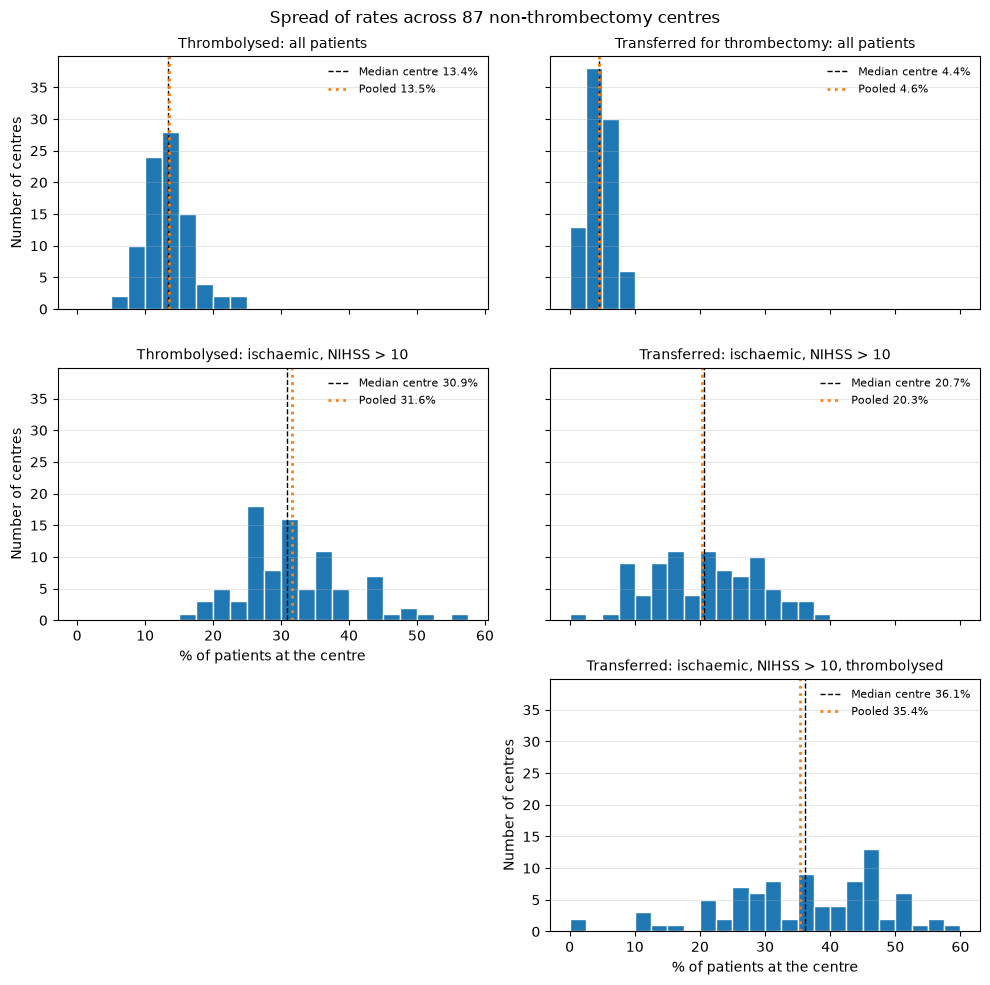

In [15]:
# Histograms of the centre-level rates (one value per non-thrombectomy centre)
# Left column: % thrombolysed; right column: % transferred for thrombectomy
panels = {
    (0, 0): ('Thrombolysed % (all)', 'Thrombolysed: all patients'),
    (0, 1): ('Transferred % (all)', 'Transferred for thrombectomy: all patients'),
    (1, 0): ('Thrombolysed % (ischaemic NIHSS>10)', 'Thrombolysed: ischaemic, NIHSS > 10'),
    (1, 1): ('Transferred % (ischaemic NIHSS>10)', 'Transferred: ischaemic, NIHSS > 10'),
    (2, 1): ('Transferred % (ischaemic NIHSS>10 thrombolysed)',
             'Transferred: ischaemic, NIHSS > 10, thrombolysed'),
}

# Same 2.5-point bins within each column so the patient groups line up
def bins_for(prefix):
    cols = [col for col, _ in panels.values() if col.startswith(prefix)]
    upper = np.ceil(non_tc_rates[cols].max().max() / 2.5) * 2.5
    return np.arange(0, upper + 2.5, 2.5)
bins = {'Thrombolysed': bins_for('Thrombolysed'), 'Transferred': bins_for('Transferred')}

fig, axes = plt.subplots(3, 2, figsize=(10, 10), sharex='col', sharey=True)
for (row, col_idx), (col, title) in panels.items():
    ax = axes[row, col_idx]
    values = non_tc_rates[col].dropna()
    ax.hist(values, bins=bins[col.split(' ')[0]], color='tab:blue',
            edgecolor='white', linewidth=1)
    ax.axvline(values.median(), color='k', linestyle='--', linewidth=1,
               label=f'Median centre {values.median():.1f}%')
    ax.axvline(spread.loc[col, 'Pooled %'], color='tab:orange', linestyle=':',
               linewidth=2, label=f"Pooled {spread.loc[col, 'Pooled %']:.1f}%")
    ax.set_title(title, fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    ax.legend(frameon=False, fontsize=8)

# No thrombolysis panel for the thrombolysed subset (it would be 100% everywhere)
axes[2, 0].axis('off')
axes[1, 0].set_xlabel('% of patients at the centre')
axes[1, 0].xaxis.set_tick_params(labelbottom=True)
axes[2, 1].set_xlabel('% of patients at the centre')
for ax in axes[:, 0]:
    ax.set_ylabel('Number of centres')
axes[2, 1].set_ylabel('Number of centres')
axes[2, 1].yaxis.set_tick_params(labelleft=True)
fig.suptitle(f'Spread of rates across {len(non_tc_rates)} non-thrombectomy centres')
plt.tight_layout()
plt.savefig('output/non_thrombectomy_centre_rates_hist.png', dpi=300, bbox_inches='tight')
plt.show()

**Results:** For all patients, both rates are tightly grouped: most centres thrombolyse 10–17.5% of admissions and transfer 2.5–7.5% for thrombectomy. Among ischaemic strokes with NIHSS > 10 the spread is much wider. Thrombolysis clusters around 25–37.5% with a long right tail up to 55%. Transfer rates spread almost evenly from about 7.5% to 35%, with no clear peak, plus one outlying centre near 0% (QVM, likely under-recorded; see above). For thrombolysed ischaemic NIHSS > 10 patients, transfer rates shift further right and spread further still, mostly between about 20% and 50%, with a cluster around 45–47.5% and two centres near 0% (QVM and WVO). In every panel the median centre and the pooled rate are close, so no single large centre dominates the pooled figure.

### Does variation in thrombolysis explain variation in transfers?

For ischaemic stroke with NIHSS > 10 at non-thrombectomy centres, this checks whether centres that thrombolyse more patients also transfer more for thrombectomy, and how much of the between-centre variation in transfer rate would remain if every centre thrombolysed at the same rate.

**What this cell does:** Uses one value per centre, for ischaemic stroke with NIHSS > 10. Two approaches:

1. **Association:** fits a straight line of transfer rate against thrombolysis rate across centres and reports the Pearson correlation, R² (the share of between-centre variance in transfer rate explained by thrombolysis rate) and the Spearman rank correlation.
2. **Standardisation:** a centre's transfer rate is a mix of its transfer rate for thrombolysed patients and for non-thrombolysed patients, weighted by how many it thrombolyses. Replacing each centre's own thrombolysis rate with the pooled rate (keeping its two transfer rates) gives the transfer rate it would have if thrombolysis use were the same everywhere. If thrombolysis drove the variation, the spread of these standardised rates would be much smaller than the observed spread.

The left panel plots thrombolysis rate against transfer rate; the right panel plots each centre's observed against standardised transfer rate (points on the dashed line are unchanged). The figure is saved to `output/non_thrombectomy_centre_thrombolysis_vs_transfer.png`.

Linear fit: transfer % = 13.3 + 0.23 x thrombolysis %
Pearson r = 0.22 (R² = 0.049, p = 0.040); Spearman rho = 0.20 (p = 0.063)
Pooled thrombolysis rate used for standardising: 31.6%
SD across centres: observed 8.2, standardised 7.8 percentage points
IQR across centres: observed 14.8–27.3%, standardised 15.8–26.2%
Between-centre variance removed by standardising thrombolysis: 9.1%
Correlation of transfer rate in thrombolysed vs non-thrombolysed patients: 0.47


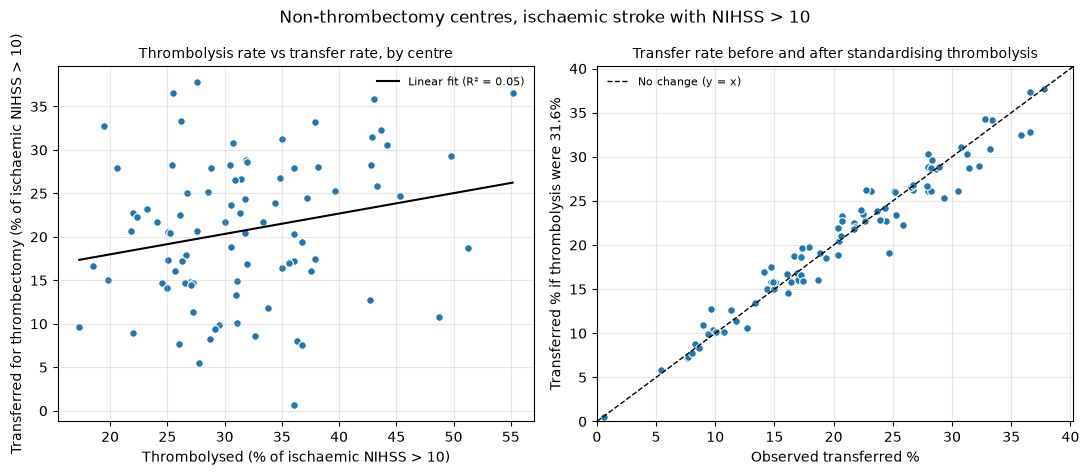

In [16]:
from scipy import stats

# Does a centre's use of thrombolysis explain its transfer rate? (ischaemic NIHSS > 10)
x = non_tc_rates['Thrombolysed % (ischaemic NIHSS>10)']
y = non_tc_rates['Transferred % (ischaemic NIHSS>10)']
fit = stats.linregress(x, y)
rho, rho_p = stats.spearmanr(x, y)

# Transfer rate within each centre, separately for patients with and without thrombolysis
by_ivt = (non_tc_severe.groupby(['stroke_team', 'thrombolysis'])['transfer_used']
          .mean().unstack() * 100)
by_ivt.columns = ['Transferred % (not thrombolysed)', 'Transferred % (thrombolysed)']

# Standardise: each centre's expected transfer rate if it thrombolysed at the pooled rate,
# keeping its own transfer rates for thrombolysed and non-thrombolysed patients
p_pooled = non_tc_severe['thrombolysis'].mean()
by_ivt['Observed transferred %'] = y
by_ivt['Standardised transferred %'] = (
    p_pooled * by_ivt['Transferred % (thrombolysed)']
    + (1 - p_pooled) * by_ivt['Transferred % (not thrombolysed)']
)

obs, std = by_ivt['Observed transferred %'], by_ivt['Standardised transferred %']
print(f'Linear fit: transfer % = {fit.intercept:.1f} + {fit.slope:.2f} x thrombolysis %')
print(f'Pearson r = {fit.rvalue:.2f} (R² = {fit.rvalue**2:.3f}, p = {fit.pvalue:.3f}); '
      f'Spearman rho = {rho:.2f} (p = {rho_p:.3f})')
print(f'Pooled thrombolysis rate used for standardising: {p_pooled * 100:.1f}%')
print(f'SD across centres: observed {obs.std():.1f}, standardised {std.std():.1f} percentage points')
print(f'IQR across centres: observed {obs.quantile(0.25):.1f}–{obs.quantile(0.75):.1f}%, '
      f'standardised {std.quantile(0.25):.1f}–{std.quantile(0.75):.1f}%')
print(f'Between-centre variance removed by standardising thrombolysis: '
      f'{(1 - std.var() / obs.var()) * 100:.1f}%')
print(f'Correlation of transfer rate in thrombolysed vs non-thrombolysed patients: '
      f'{by_ivt.iloc[:, 0].corr(by_ivt.iloc[:, 1]):.2f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

ax = axes[0]
ax.scatter(x, y, s=30, color='tab:blue', edgecolor='white', linewidth=0.8)
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(xs, fit.intercept + fit.slope * xs, color='k', linewidth=1.5,
        label=f'Linear fit (R² = {fit.rvalue**2:.2f})')
ax.set_xlabel('Thrombolysed (% of ischaemic NIHSS > 10)')
ax.set_ylabel('Transferred for thrombectomy (% of ischaemic NIHSS > 10)')
ax.set_title('Thrombolysis rate vs transfer rate, by centre', fontsize=10)
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
ax.scatter(obs, std, s=30, color='tab:blue', edgecolor='white', linewidth=0.8)
lims = [0, max(obs.max(), std.max()) + 2.5]
ax.plot(lims, lims, color='k', linestyle='--', linewidth=1, label='No change (y = x)')
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel('Observed transferred %')
ax.set_ylabel(f'Transferred % if thrombolysis were {p_pooled * 100:.1f}%')
ax.set_title('Transfer rate before and after standardising thrombolysis', fontsize=10)
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=8)

fig.suptitle('Non-thrombectomy centres, ischaemic stroke with NIHSS > 10')
plt.tight_layout()
plt.savefig('output/non_thrombectomy_centre_thrombolysis_vs_transfer.png', dpi=300,
            bbox_inches='tight')
plt.show()

**Results:** Variation in thrombolysis explains very little of the variation in transfers for thrombectomy.

* **Association:** centres that thrombolyse more do transfer slightly more: each extra 10 percentage points of thrombolysis goes with about 2.3 more points of transfer (Pearson r = 0.22, p = 0.04; Spearman rho = 0.20, p = 0.06). But R² is only 0.05, so thrombolysis rate accounts for about 5% of the between-centre variance in transfer rate. The left panel shows a wide scatter around a shallow line.
* **Standardisation:** if every centre thrombolysed at the pooled rate (31.6%), the spread of transfer rates would barely change: SD 8.2 → 7.8 percentage points and IQR 14.8–27.3% → 15.8–26.2%. This removes about 9% of the between-centre variance. In the right panel almost every centre sits close to the no-change line.
* **Centre transfer practice:** a centre's transfer rate for thrombolysed patients correlates with its rate for non-thrombolysed patients (r = 0.47). Centres that transfer a lot tend to do so whether or not the patient was thrombolysed, which suggests the variation comes mainly from each centre's own transfer practice (or its patients, pathways and distance to a thrombectomy centre) rather than from its use of thrombolysis.

These are crude, centre-level comparisons with no adjustment for case mix (for example, large vessel occlusion, onset time or travel time), so they show association, not cause.

## Do stroke teams differ in which patients they select for thrombectomy?

Looks at patients who first attended a non-thrombectomy centre (`thrombectomy_centre` = 0), so receiving thrombectomy almost always means transfer to a thrombectomy centre. Asks two questions:

1. Do teams differ in **how many** patients they send, for the same patients?
2. Do teams differ in **which** patients they send, i.e. does the weight given to age, prior disability, onset-to-arrival time, onset-time precision and stroke severity vary between teams?

These are answered with an XGBoost model of thrombectomy (patient characteristics plus stroke team), tuned with Optuna and explained with SHAP. The fitted model is then used to predict thrombectomy for the **same cohort of patients at every team**, so that differences between teams are not confounded by differences in their patients.

Note: these cells use `data_filtered` (2024–2025, ischaemic stroke, NIHSS > 10), not the 12-hour thrombectomy-only subset used above.

**What this cell does:** Selects patients in `data_filtered` who first attended a non-thrombectomy centre (`transfer_cohort`) and creates 0/1 flags for the characteristics compared: age 80 or over (`age80`), prior mRS 2 or more (`mrs2`), NIHSS 21 or more (`nihss21`), arrival more than 4 hours after onset or onset-to-arrival time unknown (`late`), and onset time not precisely known (`imprecise`). It then cross-tabulates `transfer_used` against `thrombectomy` to check that thrombectomy is a good marker of transfer.

In [17]:
import warnings
from scipy import stats

# Patients first attending a non-thrombectomy centre
transfer_cohort = data_filtered[data_filtered['thrombectomy_centre'] == 0].copy()

# 0/1 patient characteristic flags
transfer_cohort['age80'] = (transfer_cohort['age'] >= 80).astype(int)
transfer_cohort['mrs2'] = (transfer_cohort['prior_disability'] >= 2).astype(int)
transfer_cohort['nihss21'] = (transfer_cohort['stroke_severity'] >= 21).astype(int)
transfer_cohort['late'] = ((transfer_cohort['onset_to_arrival_time'] > 240) |
                           transfer_cohort['onset_to_arrival_time'].isna()).astype(int)
transfer_cohort['imprecise'] = (transfer_cohort['precise_onset_known'] == 0).astype(int)
transfer_cohort['team'] = transfer_cohort['stroke_team'].astype(str)

selection_features = ['age80', 'mrs2', 'nihss21', 'late', 'imprecise']

print(f"Patients: {len(transfer_cohort):,}; teams: {transfer_cohort['team'].nunique()}")
pd.crosstab(transfer_cohort['transfer_used'], transfer_cohort['thrombectomy'])

Patients: 18,296; teams: 87


thrombectomy,0,1
transfer_used,,
0,14446,139
1,600,3111


**Results:** 18,296 patients first attended one of 87 non-thrombectomy teams. 3,111 were transferred and received thrombectomy, 600 were transferred but did not receive thrombectomy, and 139 received thrombectomy with no transfer recorded. Thrombectomy is therefore used below as the measure of transfer for thrombectomy.

**What this cell does:** Calculates the proportion of patients receiving thrombectomy for each team and summarises how this varies between teams.

In [18]:
team_rates = transfer_cohort.groupby('team').agg(
    patients=('thrombectomy', 'size'), thrombectomy_rate=('thrombectomy', 'mean'))
team_rates.describe().round(3)

,patients,thrombectomy_rate
count,87.000,87.000
mean,210.299,0.180
std,103.485,0.072
min,44.000,0.055
25%,133.500,0.128
50%,200.000,0.174
75%,265.500,0.235
max,458.000,0.357


**Results:** Team thrombectomy rates range from 5.5% to 35.7% (median 17.4%; interquartile range 12.8–23.5%). Teams have between 44 and 458 patients (median 200).

**What this cell does:** Builds the model data: 15 patient characteristics (age, sex, NIHSS, prior mRS, onset-to-arrival time, whether onset time is known or precise, onset during sleep, arrival by ambulance and comorbidities) plus one 0/1 column per stroke team. Missing values (mainly onset-to-arrival time, 18% missing) are left as missing, which XGBoost handles directly. The data are split into a training set (80%) and a held-out test set (20%), stratified by thrombectomy. Optuna (TPE sampler, 50 trials, fixed seed) then tunes the XGBoost hyperparameters to maximise the mean ROC AUC from 5-fold stratified cross-validation on the training set. This takes about 5 minutes, so the result is saved to `output/xgb_tuning.json`. If `retune_model` (set at the start of the notebook) is False and that file exists, the saved hyperparameters are loaded instead of re-tuning.

In [19]:
import optuna
import json
import os
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score
from sklearn.metrics import roc_auc_score, brier_score_loss

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

patient_features = [
    'age', 'male', 'stroke_severity', 'prior_disability', 'onset_to_arrival_time',
    'onset_known', 'precise_onset_known', 'onset_during_sleep', 'arrive_by_ambulance',
    'congestive_heart_failure', 'hypertension', 'atrial_fibrillation', 'diabetes',
    'prior_stroke_tia', 'afib_anticoagulant']

# Patient characteristics plus one 0/1 column per stroke team
team_dummies = pd.get_dummies(transfer_cohort['stroke_team'], prefix='team', dtype=float)
team_cols = list(team_dummies.columns)
X = pd.concat([transfer_cohort[patient_features].astype(float), team_dummies], axis=1)
y = transfer_cohort['thrombectomy'].astype(int).values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def objective(trial):
    params = dict(
        n_estimators=trial.suggest_int('n_estimators', 100, 1000),
        learning_rate=trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        max_depth=trial.suggest_int('max_depth', 2, 8),
        min_child_weight=trial.suggest_float('min_child_weight', 1, 20, log=True),
        subsample=trial.suggest_float('subsample', 0.5, 1.0),
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.3, 1.0),
        reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
        reg_alpha=trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
    )
    model = xgb.XGBClassifier(**params, tree_method='hist', n_jobs=-1,
                              random_state=42, eval_metric='logloss')
    return cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc').mean()

# Tuning is slow (~5 min), so the result is saved and reloaded on later runs.
# Set retune_model = True at the start of the notebook to re-tune (e.g. after changing the data);
# a new tuning is also run if no saved file exists.
tuning_file = 'output/xgb_tuning.json'
if os.path.exists(tuning_file) and not retune_model:
    with open(tuning_file) as f:
        tuning = json.load(f)
    print(f'Loaded tuned hyperparameters from {tuning_file}')
else:
    study = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=50)
    tuning = {'best_params': study.best_params, 'best_value': study.best_value}
    with open(tuning_file, 'w') as f:
        json.dump(tuning, f, indent=2)
    print(f'Saved tuned hyperparameters to {tuning_file}')

best_params = dict(tuning['best_params'], tree_method='hist', n_jobs=-1,
                   random_state=42, eval_metric='logloss')
print(f"Best cross-validated ROC AUC: {tuning['best_value']:.3f}")
pd.Series(tuning['best_params']).round(3)

Loaded tuned hyperparameters from output/xgb_tuning.json
Best cross-validated ROC AUC: 0.838


n_estimators        474.000
learning_rate         0.094
max_depth             2.000
min_child_weight      3.449
subsample             0.771
colsample_bytree      0.317
reg_lambda            0.170
reg_alpha             0.280
dtype: float64

**Results:** The best of 50 trials had a mean cross-validated ROC AUC of 0.838. The selected model uses shallow trees (maximum depth 2; 474 trees; learning rate 0.094; 32% of features sampled per tree), which still allow pairwise interactions such as between team and a patient characteristic.

**Note:** these hyperparameters were loaded from `output/xgb_tuning.json`, which was saved when the model was tuned on an earlier version of the data file. Set `retune_model = True` at the start of the notebook and re-run to re-tune on the current data.

**What this cell does:** Fits the tuned model on the training set and evaluates it on the held-out test set: ROC AUC, Brier score, observed versus mean predicted thrombectomy rate, and calibration by decile of predicted probability. For comparison, the same model is also fitted using patient characteristics only (no team columns), to show how much knowing the team adds.

In [20]:
model_train = xgb.XGBClassifier(**best_params).fit(X_train, y_train)
p_test = model_train.predict_proba(X_test)[:, 1]

model_no_team = xgb.XGBClassifier(**best_params).fit(X_train[patient_features], y_train)
p_test_no_team = model_no_team.predict_proba(X_test[patient_features])[:, 1]

print(f'Test ROC AUC (patients + team): {roc_auc_score(y_test, p_test):.3f}')
print(f'Test ROC AUC (patients only):   {roc_auc_score(y_test, p_test_no_team):.3f}')
print(f'Brier score: {brier_score_loss(y_test, p_test):.3f}')
print(f'Observed rate {y_test.mean():.3f}; mean predicted {p_test.mean():.3f}')

# Calibration by decile of predicted probability
calibration = pd.DataFrame({'Predicted': p_test, 'Observed': y_test})
calibration['Decile'] = pd.qcut(calibration['Predicted'], 10, labels=False) + 1
calibration.groupby('Decile').mean().round(3).T

Test ROC AUC (patients + team): 0.831
Test ROC AUC (patients only):   0.816
Brier score: 0.116
Observed rate 0.178; mean predicted 0.182


Decile,1,2,3,4,5,6,7,8,9,10
Predicted,0.003,0.009,0.019,0.042,0.084,0.149,0.224,0.312,0.412,0.567
Observed,0.000,0.008,0.011,0.044,0.079,0.189,0.216,0.303,0.418,0.508


**Results:** On the held-out test set the model discriminates well (ROC AUC 0.831) and is well calibrated: the mean predicted rate (18.2%) matches the observed rate (17.8%), and observed rates track predicted rates across deciles (from 0% in the lowest decile to 51% in the highest). Without team information the ROC AUC falls to 0.816, so the team a patient first attends adds to the prediction beyond patient characteristics.

**What this cell does:** Refits the tuned model on all patients and calculates SHAP values (TreeExplainer), which split each prediction (in log-odds) into contributions from each feature. The SHAP values of the 87 team columns are summed into a single **Stroke team** contribution. The left panel shows mean |SHAP| (overall importance) for each patient characteristic and for team; the right panel shows each team's mean team SHAP value (its typical effect on the log-odds of thrombectomy). The figure is saved to `output/xgb_shap.png`.

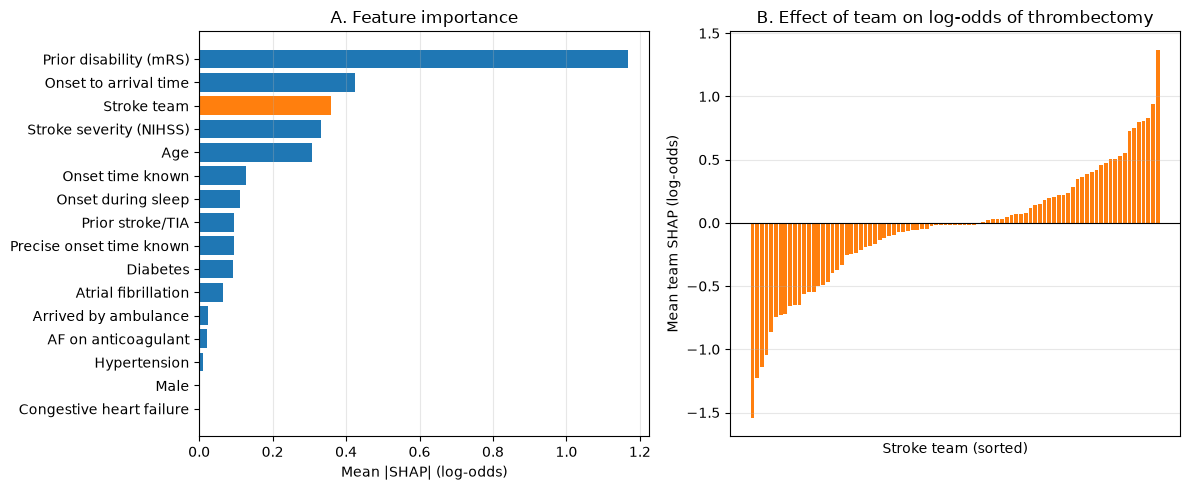

Mean |SHAP|:
prior_disability            1.167
onset_to_arrival_time       0.423
Stroke team                 0.360
stroke_severity             0.331
age                         0.308
onset_known                 0.128
onset_during_sleep          0.110
prior_stroke_tia            0.095
precise_onset_known         0.095
diabetes                    0.092
atrial_fibrillation         0.064
arrive_by_ambulance         0.025
afib_anticoagulant          0.020
hypertension                0.011
male                        0.003
congestive_heart_failure    0.003
Team SHAP 10th/50th/90th centile: -0.65 / -0.02 / 0.52 (range -1.54 to 1.37)


In [21]:
import shap

model = xgb.XGBClassifier(**best_params).fit(X, y)
shap_values = shap.TreeExplainer(model).shap_values(X)
shap_df = pd.DataFrame(shap_values, columns=X.columns, index=X.index)
shap_df['Stroke team'] = shap_df[team_cols].sum(axis=1)

feature_labels = {
    'prior_disability': 'Prior disability (mRS)', 'onset_to_arrival_time': 'Onset to arrival time',
    'stroke_severity': 'Stroke severity (NIHSS)', 'age': 'Age', 'onset_during_sleep': 'Onset during sleep',
    'prior_stroke_tia': 'Prior stroke/TIA', 'diabetes': 'Diabetes',
    'precise_onset_known': 'Precise onset time known', 'atrial_fibrillation': 'Atrial fibrillation',
    'onset_known': 'Onset time known', 'arrive_by_ambulance': 'Arrived by ambulance', 'male': 'Male',
    'afib_anticoagulant': 'AF on anticoagulant', 'hypertension': 'Hypertension',
    'congestive_heart_failure': 'Congestive heart failure', 'Stroke team': 'Stroke team'}

importance = shap_df[patient_features + ['Stroke team']].abs().mean().sort_values()
team_shap = shap_df.groupby(transfer_cohort['stroke_team'].values)['Stroke team'].mean().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ax = axes[0]
colours = ['tab:orange' if f == 'Stroke team' else 'tab:blue' for f in importance.index]
ax.barh([feature_labels[f] for f in importance.index], importance.values, color=colours)
ax.set_xlabel('Mean |SHAP| (log-odds)')
ax.set_title('A. Feature importance')
ax.grid(axis='x', alpha=0.3)
ax = axes[1]
ax.bar(range(len(team_shap)), team_shap.values, color='tab:orange')
ax.axhline(0, color='k', linewidth=0.8)
ax.set_xticks([])
ax.set_xlabel('Stroke team (sorted)')
ax.set_ylabel('Mean team SHAP (log-odds)')
ax.set_title('B. Effect of team on log-odds of thrombectomy')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('output/xgb_shap.png', dpi=300, bbox_inches='tight')
plt.show()

print('Mean |SHAP|:')
print(importance.sort_values(ascending=False).round(3).to_string())
q = team_shap.quantile([0.1, 0.5, 0.9])
print(f'Team SHAP 10th/50th/90th centile: {q[0.1]:.2f} / {q[0.5]:.2f} / {q[0.9]:.2f} '
      f'(range {team_shap.min():.2f} to {team_shap.max():.2f})')

**Results:** Prior disability is by far the most important feature (mean |SHAP| 1.17), followed by onset-to-arrival time (0.42). **Stroke team is the third most important feature (0.36)**, ahead of stroke severity (0.33) and age (0.31). Other characteristics contribute little (each ≤ 0.13). Team effects range from −1.54 to +1.37 log-odds; between the 10th and 90th centile teams they range from −0.65 to +0.52, a difference of about 1.2 log-odds (an odds ratio of about 3.2).

**What this cell does:** Uses out-of-fold predictions from the tuned model (patients are split into 5 folds stratified by team, and each patient is predicted only by a model trained on the other 4 folds) to ask what each team would do with **the same patients**. All 18,296 patients are passed through the model 87 times, each time with the team set to one of the 87 teams, giving each team's predicted thrombectomy rate for an identical cohort. For each team it then calculates an odds ratio for each of the 15 patient features in the model, using each feature's actual values with no cut-points: the exponentiated slope of the team's predicted log-odds on the feature across the same patients. Continuous features (age, NIHSS, prior mRS, onset-to-arrival time) are standardised, giving the odds ratio per 1 SD; 0/1 features give the odds ratio for present vs absent; missing values are excluded for that feature only. The spread of these odds ratios across teams shows whether teams differ in **which** patients they select; the Spearman correlation with each team's overall predicted log-odds shows whether teams that treat more patients extend thrombectomy to more marginal patients. Odds ratios are used rather than ratios of rates, because ratios of rates move towards 1 as the overall rate rises even when selection is identical. The left panel of the figure plots each team's observed rate against the mean out-of-fold predicted rate for its own patients, with R² and p value from a linear regression across teams; the same-patient rates are summarised in the printed output. The right panel puts both kinds of variation on one scale, relative to the average team: the orange row is each team's overall effect on the odds of thrombectomy for the same patients (how many), and each blue row is how far each team's odds ratio for a feature differs from the average team's (which patients). Each dot is a team; black bars span the 10th to 90th centile teams. The figure is saved to `output/xgb_same_patient_comparison.png`, and the table to `output/xgb_team_selection.csv`.

Out-of-fold ROC AUC (actual team): 0.840
Predicted rate for the same patients, 10th/50th/90th centile team: 11.3% / 17.7% / 24.5% (range 5.2% to 35.4%)
Odds multiplier relative to average team, 10th/90th centile: 0.55 / 1.75 (90th vs 10th: 3.2)
Spearman correlation, observed vs same-patient rate: 0.93
Observed vs same-patient rate: R² = 0.84, p = 7.1e-36 (slope 0.69)
Observed vs own-patient predicted rate: R² = 0.97, p < 0.001 (slope 0.81)
Relative to average team, 10th / 90th centile team:
  Team overall effect (same patients): 0.55 / 1.75
  Relative odds ratio: Age (per SD): 0.98 / 1.02
  Relative odds ratio: Male: 0.97 / 1.02
  Relative odds ratio: NIHSS (per SD): 0.97 / 1.02
  Relative odds ratio: Prior mRS (per SD): 0.97 / 1.02
  Relative odds ratio: Onset to arrival time (per SD): 0.99 / 1.01
  Relative odds ratio: Onset time known: 0.94 / 1.04
  Relative odds ratio: Precise onset time known: 0.96 / 1.04
  Relative odds ratio: Onset during sleep: 0.97 / 1.03
  Relative odds ratio

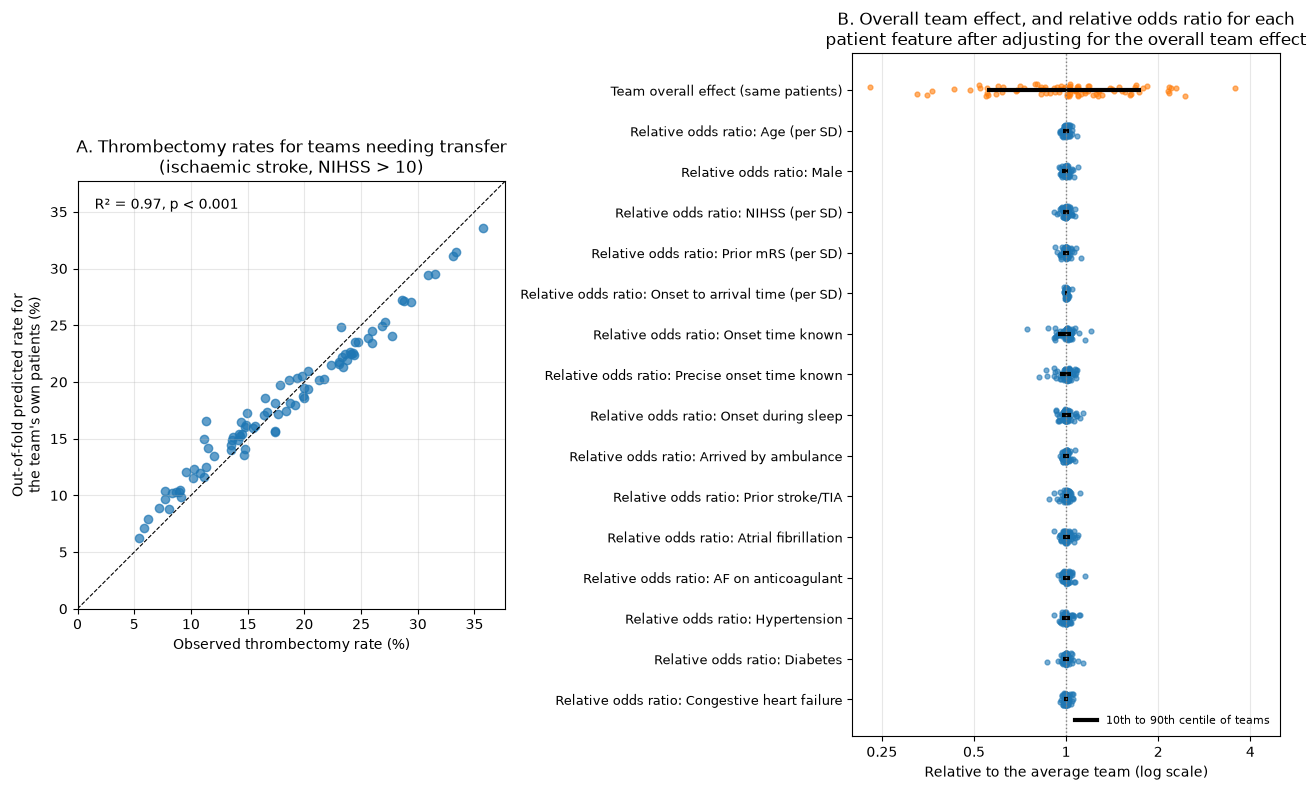

,Unit,Mean (or % present),% missing,"OR, all teams","OR, 10th centile team","OR, 90th centile team","OR, min","OR, max",Spearman rho vs team log-odds,p
Characteristic,,,,,,,,,,
Age (per SD),1 SD = 12.6,77.679,0.000,0.428,0.419,0.439,0.408,0.465,-0.182,0.092
Male,present vs absent,46.072,0.016,1.984,1.924,2.019,1.885,2.175,0.037,0.733
NIHSS (per SD),1 SD = 5.5,17.847,0.000,1.107,1.079,1.133,1.011,1.181,0.010,0.927
Prior mRS (per SD),1 SD = 1.6,1.598,0.000,0.203,0.198,0.207,0.187,0.227,-0.417,0.000
Onset to arrival time (per SD),1 SD = 1813.9,467.566,18.305,0.742,0.737,0.748,0.728,0.773,-0.193,0.074
Onset time known,present vs absent,81.695,0.000,3.535,3.315,3.681,2.627,4.251,0.116,0.286
Precise onset time known,present vs absent,36.456,0.000,3.119,2.978,3.231,2.544,3.384,0.138,0.203
Onset during sleep,present vs absent,12.035,0.000,1.064,1.034,1.100,0.984,1.210,-0.052,0.631
Arrived by ambulance,present vs absent,91.525,0.361,0.826,0.807,0.842,0.791,0.884,-0.054,0.621


In [22]:
# Predict the same cohort of patients at every team, using out-of-fold predictions:
# patients are split into 5 folds (stratified by team), and each patient's predictions
# for every team come from a model trained only on the other 4 folds.
oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
team_names = [col.replace('team_', '') for col in team_cols]
same_patient = pd.DataFrame(np.nan, index=X.index, columns=team_names)
oof_pred = np.full(len(X), np.nan)
for fold, (train_idx, test_idx) in enumerate(
        oof_cv.split(X, transfer_cohort['stroke_team'].astype(str))):
    fold_model = xgb.XGBClassifier(**best_params).fit(X.iloc[train_idx], y[train_idx])
    X_fold = X.iloc[test_idx]
    oof_pred[test_idx] = fold_model.predict_proba(X_fold)[:, 1]
    for j, col in enumerate(team_cols):
        X_team = X_fold.copy()
        X_team[team_cols] = 0.0
        X_team[col] = 1.0
        same_patient.iloc[test_idx, j] = fold_model.predict_proba(X_team)[:, 1]
assert not same_patient.isna().any().any()
print(f'Out-of-fold ROC AUC (actual team): {roc_auc_score(y, oof_pred):.3f}')
same_patient_logit = np.log(same_patient / (1 - same_patient))

team_rate_same = same_patient.mean()
team_logit_same = same_patient_logit.mean()
observed_rate = transfer_cohort.groupby('stroke_team')['thrombectomy'].mean().loc[team_rate_same.index]

q = team_rate_same.quantile([0.1, 0.5, 0.9]) * 100
print(f'Predicted rate for the same patients, 10th/50th/90th centile team: '
      f'{q[0.1]:.1f}% / {q[0.5]:.1f}% / {q[0.9]:.1f}% '
      f'(range {team_rate_same.min()*100:.1f}% to {team_rate_same.max()*100:.1f}%)')
centred = team_logit_same - team_logit_same.mean()
print(f'Odds multiplier relative to average team, 10th/90th centile: '
      f'{np.exp(centred.quantile(0.1)):.2f} / {np.exp(centred.quantile(0.9)):.2f} '
      f'(90th vs 10th: {np.exp(centred.quantile(0.9) - centred.quantile(0.1)):.1f})')
print(f'Spearman correlation, observed vs same-patient rate: '
      f'{stats.spearmanr(observed_rate, team_rate_same)[0]:.2f}')

# Per-team odds ratio for each of the 15 patient features in the model, using each feature's
# actual values (no cut-points): the slope of each team's predicted log-odds on the feature
# across the same patients. Continuous features are standardised, giving the odds ratio per
# 1 SD; 0/1 features give the odds ratio for present vs absent. Missing values are excluded
# for that feature only.
feature_names = {
    'age': 'Age', 'male': 'Male', 'stroke_severity': 'NIHSS',
    'prior_disability': 'Prior mRS', 'onset_to_arrival_time': 'Onset to arrival time',
    'onset_known': 'Onset time known', 'precise_onset_known': 'Precise onset time known',
    'onset_during_sleep': 'Onset during sleep', 'arrive_by_ambulance': 'Arrived by ambulance',
    'prior_stroke_tia': 'Prior stroke/TIA', 'atrial_fibrillation': 'Atrial fibrillation',
    'afib_anticoagulant': 'AF on anticoagulant', 'hypertension': 'Hypertension',
    'diabetes': 'Diabetes', 'congestive_heart_failure': 'Congestive heart failure'}
assert set(feature_names) == set(patient_features)

selection_rows, team_odds_ratios = [], {}
for feature, label in feature_names.items():
    x = transfer_cohort[feature].astype(float)
    present = x.notna().values
    x = x[present]
    binary = set(x.unique()) <= {0.0, 1.0}
    name = label if binary else f'{label} (per SD)'
    z = x if binary else (x - x.mean()) / x.std()
    z = (z - z.mean()).values
    slope = same_patient_logit[present].mul(z, axis=0).sum() / (z ** 2).sum()
    team_odds_ratios[name] = np.exp(slope)
    rho, p = stats.spearmanr(team_logit_same, slope.loc[team_logit_same.index])
    selection_rows.append({
        'Characteristic': name,
        'Unit': 'present vs absent' if binary else f'1 SD = {x.std():.1f}',
        'Mean (or % present)': 100 * x.mean() if binary else x.mean(),
        '% missing': 100 * (1 - present.mean()),
        'OR, all teams': np.exp(slope.mean()),
        'OR, 10th centile team': np.exp(slope.quantile(0.1)),
        'OR, 90th centile team': np.exp(slope.quantile(0.9)),
        'OR, min': np.exp(slope.min()), 'OR, max': np.exp(slope.max()),
        'Spearman rho vs team log-odds': rho, 'p': p})
team_selection = pd.DataFrame(selection_rows).set_index('Characteristic')
team_selection.round(3).to_csv('output/xgb_team_selection.csv')

# Same-patient rates vs observed rates (reported, not plotted)
lr_same = stats.linregress(observed_rate, team_rate_same)
print(f'Observed vs same-patient rate: R² = {lr_same.rvalue**2:.2f}, '
      f'p = {lr_same.pvalue:.2g} (slope {lr_same.slope:.2f})')

# Panel A: each team's own patients, mean out-of-fold prediction (actual team) vs observed rate
own_rate = (pd.Series(oof_pred, index=X.index)
            .groupby(transfer_cohort['stroke_team']).mean().loc[team_rate_same.index])

fig, axes = plt.subplots(1, 2, figsize=(13, 8))
axes[0].set_box_aspect(1)  # keep panel A square while panel B is taller
ax = axes[0]
ax.scatter(observed_rate * 100, own_rate * 100, color='tab:blue', alpha=0.7)
lim = [0, max(observed_rate.max(), own_rate.max()) * 100 + 2]
ax.plot(lim, lim, 'k--', linewidth=0.8)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('Observed thrombectomy rate (%)')
ax.set_ylabel("Out-of-fold predicted rate for\nthe team's own patients (%)")
ax.set_title('A. Thrombectomy rates for teams needing transfer\n(ischaemic stroke, NIHSS > 10)')
ax.grid(alpha=0.3)
# Linear fit of predicted (own patients) vs observed team rates
lr = stats.linregress(observed_rate, own_rate)
p_text = 'p < 0.001' if lr.pvalue < 0.001 else f'p = {lr.pvalue:.3f}'
print(f'Observed vs own-patient predicted rate: R² = {lr.rvalue**2:.2f}, {p_text} (slope {lr.slope:.2f})')
ax.text(0.04, 0.96, f'R² = {lr.rvalue**2:.2f}, {p_text}', transform=ax.transAxes, va='top')
# Panel B: how much teams differ in HOW MANY patients (overall team effect) versus
# WHICH patients (team odds ratio for each characteristic), both relative to the
# average team on the same log scale
ax = axes[1]
relative = {'Team overall effect (same patients)': np.exp(centred)}
for name, ors in team_odds_ratios.items():
    log_ors = np.log(ors)
    relative[f'Relative odds ratio: {name}'] = np.exp(log_ors - log_ors.mean())
rng = np.random.default_rng(42)
n_rows = len(relative)
print('Relative to average team, 10th / 90th centile team:')
for i, (name, vals) in enumerate(relative.items()):
    y_pos = n_rows - 1 - i
    colour = 'tab:orange' if i == 0 else 'tab:blue'
    ax.scatter(vals, y_pos + rng.uniform(-0.15, 0.15, len(vals)), s=12, alpha=0.6, color=colour)
    lo, hi = np.quantile(vals, [0.1, 0.9])
    ax.plot([lo, hi], [y_pos, y_pos], color='k', linewidth=3, solid_capstyle='butt')
    print(f"  {name.replace(chr(10), ' ')}: {lo:.2f} / {hi:.2f}")
ax.set_xscale('log')
ticks = [0.25, 0.5, 1, 2, 4]
ax.set_xticks(ticks)
ax.set_xticklabels([str(t) for t in ticks])
ax.set_xlim(0.2, 5)
ax.minorticks_off()
ax.set_yticks(range(n_rows))
ax.set_yticklabels(list(relative)[::-1], fontsize=9)
ax.axvline(1, color='grey', linestyle=':', linewidth=1)
ax.set_xlabel('Relative to the average team (log scale)')
ax.set_title('B. Overall team effect, and relative odds ratio for each\n'
             'patient feature after adjusting for the overall team effect')
ax.plot([], [], color='k', linewidth=3, label='10th to 90th centile of teams')
ax.legend(loc='lower right', fontsize=8, frameon=False)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('output/xgb_same_patient_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

team_selection.round(3)

**Results:** The cohort is patients with ischaemic stroke and NIHSS > 10 who first attended one of the 87 teams needing transfer for thrombectomy. The left panel compares each team's observed thrombectomy rate with the mean out-of-fold prediction for its own patients: the model reproduces team rates closely (R² = 0.97, p < 0.001), with a slope of 0.81, so the most extreme teams are pulled somewhat towards the average (as expected from a regularised model predicting patients it was not trained on). The out-of-fold model discriminates well (ROC AUC 0.840, using each patient's actual team), similar to the held-out test set (0.831).

When every team is given the same 18,296 patients, out-of-fold predicted thrombectomy rates still vary widely: 11.3% at the 10th centile team, 17.7% at the median and 24.5% at the 90th centile (range 5.2% to 35.4%). On the odds scale, the 90th centile team is about 3.2 times as likely as the 10th centile team to give thrombectomy to the same patient (odds multipliers 0.55 and 1.75 relative to the average team). Same-patient rates are closely related to observed rates (R² = 0.84, p < 0.001; Spearman ρ = 0.93), so differences in case mix explain little of the observed variation.

By contrast, teams weigh patient features very similarly. The right panel shows, for each of the 15 patient features in the model, each team's odds ratio relative to the average team, using the feature's actual values (odds ratio per 1 SD for age, NIHSS, prior mRS and onset-to-arrival time; present vs absent for the 0/1 features). While the orange row spans 0.55 to 1.75 between the 10th and 90th centile teams, every blue row stays within about 6% of the average team. For example, odds ratios at the 10th and 90th centile teams are 0.42 and 0.44 per SD of age (12.6 years), 0.20 and 0.21 per SD of prior mRS (1.6 points), 1.08 and 1.13 per SD of NIHSS (5.5 points), and 3.32 and 3.68 for a known onset time. Teams that treat more patients do not extend thrombectomy to more marginal patients. Where there is an association, it runs the other way: higher-rate teams are slightly more selective on prior mRS (Spearman ρ = −0.42, p < 0.001), congestive heart failure (ρ = −0.32, p = 0.002), AF on anticoagulant (ρ = −0.26, p = 0.017), atrial fibrillation (ρ = −0.25, p = 0.021) and prior stroke/TIA (ρ = −0.24, p = 0.024). Prior mRS and congestive heart failure remain significant after Bonferroni correction for 15 tests (p < 0.0033). The other ten features show no association (|ρ| ≤ 0.20, p ≥ 0.07).

These odds ratios are marginal: each is the slope of predicted log-odds on one feature across the same patients, so it also reflects the other features that go with it (for example, older patients more often have prior disability). Onset-to-arrival time is highly skewed (mean 468 minutes, SD 1,814 minutes) and is missing for 18% of patients, who are excluded from that row only.

**What this cell does:** For teams with at least 20 thrombectomy patients, describes the patients each team sent (proportion aged ≥ 80, with prior mRS ≥ 2, arriving > 4 h or unknown, and mean NIHSS), and uses Spearman correlation to test whether teams with higher thrombectomy rates send different types of patients.

In [23]:
treated_profile = transfer_cohort[transfer_cohort['thrombectomy'] == 1].groupby('team').agg(
    n_thrombectomy=('thrombectomy', 'size'), age80=('age80', 'mean'), mrs2=('mrs2', 'mean'),
    late=('late', 'mean'), mean_nihss=('stroke_severity', 'mean'))
team_profile = team_rates.join(treated_profile)
team_profile = team_profile[team_profile['n_thrombectomy'] >= 20]

print(f'Teams with at least 20 thrombectomy patients: {len(team_profile)}')
for col in ['age80', 'mrs2', 'late', 'mean_nihss']:
    rho, p = stats.spearmanr(team_profile['thrombectomy_rate'], team_profile[col])
    print(f'Thrombectomy rate vs {col}: rho = {rho:.2f}, p = {p:.2g}')
team_profile[['thrombectomy_rate', 'age80', 'mrs2', 'late', 'mean_nihss']].describe(
    percentiles=[0.1, 0.5, 0.9]).round(3).T[['10%', '50%', '90%']]

Teams with at least 20 thrombectomy patients: 66
Thrombectomy rate vs age80: rho = 0.05, p = 0.67
Thrombectomy rate vs mrs2: rho = 0.04, p = 0.74
Thrombectomy rate vs late: rho = 0.13, p = 0.3
Thrombectomy rate vs mean_nihss: rho = -0.19, p = 0.13


,10%,50%,90%
thrombectomy_rate,0.117,0.196,0.287
age80,0.204,0.313,0.417
mrs2,0.031,0.108,0.207
late,0.164,0.267,0.427
mean_nihss,16.908,18.295,19.921


**Results:** Across 66 teams, the patients sent for thrombectomy vary. Aged ≥ 80: 20–42% (10th–90th centile); prior mRS ≥ 2: 3–21%; arrival > 4 h or unknown: 16–43%. Teams with higher thrombectomy rates do not send older, more disabled or later-arriving patients: none of the correlations is significant (ρ between −0.19 and 0.13).

### Summary: team differences in selection for thrombectomy transfer

- The main difference between non-thrombectomy teams is **how many** patients go on to thrombectomy, not **which** ones. Given the same 18,296 patients (ischaemic stroke, NIHSS > 10), out-of-fold predictions from the tuned XGBoost model give thrombectomy rates of 11.3% at the 10th centile team and 24.5% at the 90th centile team (odds about 3.2-fold higher for the same patient). Same-patient rates closely track observed rates (R² = 0.84, p < 0.001).
- Stroke team is the third most important feature in the model (SHAP), after prior disability and onset-to-arrival time, and adding team improves the test ROC AUC from 0.816 to 0.831.
- Teams weigh all 15 patient features in the model very similarly (each team's odds ratio for every feature is within about 6% of the average team's), and teams that transfer more do not extend thrombectomy to more marginal patients. If anything, higher-rate teams are slightly more selective on prior disability and congestive heart failure (the two associations that survive correction for multiple testing), with weaker associations in the same direction for atrial fibrillation, AF on anticoagulant and prior stroke/TIA.

**Caveats:**

- The team effect may reflect distance to the thrombectomy centre, the receiving centre's acceptance practice or access to CT angiography, as well as referral decisions.
- Imaging was not included (LVO missing for 38%, ASPECTS for 63%), so imaging-based selection is absorbed into the team effect.
- The outcome is completed thrombectomy, not referral.
- The model is regularised and uses shallow trees; team-specific differences in selection that are small, or confined to small teams, may not be detected.

## Thrombectomy units and variation between referring teams

Which stroke team a patient first attends strongly affects whether they are transferred for thrombectomy. Each stroke team transfers to one thrombectomy unit (`MT_transfer_unit`). These cells look at how teams' thrombectomy rates relate to the thrombectomy unit they transfer to, and to that unit's thrombectomy rate for its own patients.

**Note:** these cells use `data_filtered` from above (ischaemic stroke, NIHSS > 10, 2024–2025), not the 12-hour thrombectomy subset.

**What this cell does:** Selects patients who first attended a non-thrombectomy centre (`thrombectomy_centre` = 0) and have a known `MT_transfer_unit`, and stores them as `transfer_data`. Checks that each stroke team maps to a single thrombectomy unit, and counts patients, teams and units.

In [24]:
# Patients who first attended a non-thrombectomy centre, with a known thrombectomy unit
transfer_data = data_filtered[
    (data_filtered['thrombectomy_centre'] == 0) & (data_filtered['MT_transfer_unit'].notna())
].copy()

# Check each stroke team maps to a single thrombectomy unit
units_per_team = transfer_data.groupby('stroke_team')['MT_transfer_unit'].nunique()
print(f"Teams with more than one MT_transfer_unit: {(units_per_team > 1).sum()}")

print(f"Patients: {len(transfer_data):,}")
print(f"Stroke teams: {transfer_data['stroke_team'].nunique()}")
print(f"Thrombectomy units: {transfer_data['MT_transfer_unit'].nunique()}")
print(f"Proportion receiving thrombectomy: {transfer_data['thrombectomy'].mean():.3f}")
print(f"Proportion of thrombectomies with transfer recorded: "
      f"{transfer_data.loc[transfer_data['thrombectomy'] == 1, 'transfer_used'].mean():.3f}")

Teams with more than one MT_transfer_unit: 0
Patients: 18,189
Stroke teams: 86
Thrombectomy units: 21
Proportion receiving thrombectomy: 0.178
Proportion of thrombectomies with transfer recorded: 0.957


**Results:** 18,189 patients from 86 stroke teams, transferring to 21 thrombectomy units (about 4 teams per unit). Every team has a single `MT_transfer_unit`, so the unit is a property of the team, not of the patient. 17.8% received thrombectomy, and 95.7% of these had a transfer recorded, so for these patients thrombectomy is effectively transfer for thrombectomy.

**What this cell does:** Calculates the proportion receiving thrombectomy for each stroke team (`team_rates`) and each thrombectomy unit (`unit_rates`, all patients from that unit's teams pooled), and summarises the spread of each.

In [25]:
# Thrombectomy (transfer) rate per stroke team and per thrombectomy unit
team_rates = transfer_data.groupby('stroke_team').agg(
    unit=('MT_transfer_unit', 'first'),
    rate=('thrombectomy', 'mean'),
    n=('thrombectomy', 'size'))

unit_rates = transfer_data.groupby('MT_transfer_unit').agg(
    rate=('thrombectomy', 'mean'),
    n=('thrombectomy', 'size'),
    teams=('stroke_team', 'nunique'))

quantiles = [0, 0.25, 0.5, 0.75, 1]
summary_rates = pd.DataFrame({
    'Stroke teams (%)': team_rates['rate'].quantile(quantiles) * 100,
    'Thrombectomy units (%)': unit_rates['rate'].quantile(quantiles) * 100,
}, index=quantiles).rename(index={0: 'min', 0.25: '25%', 0.5: 'median', 0.75: '75%', 1: 'max'})
summary_rates.round(1)

,Stroke teams (%),Thrombectomy units (%)
min,5.5,6.7
25%,12.4,13.5
median,17.6,16.6
75%,23.5,22.5
max,35.7,28.0


**Results:** Team rates range from 5.5% to 35.7% (IQR 12.4–23.5%). Unit rates are almost as spread out: 6.7% to 28.0% (IQR 13.5–22.5%). Much of the variation between teams is therefore also present between units.

### Team thrombectomy rates grouped by thrombectomy unit

**What this cell does:** Plots, for each thrombectomy unit (one row each, sorted by the thrombectomy rate of the unit's own patients), the thrombectomy rate of each stroke team that transfers to it (blue) and of the unit's own patients, who first attended the thrombectomy unit (red). Circle area is proportional to the number of thrombectomies. The light blue band shows the range (lowest to highest) of the transferring teams' rates for each unit. The black tick is the rate for all patients of the unit's transferring teams, the grey dashed line is the rate for all patients first attending a non-thrombectomy centre, and the red dashed line is the rate for all patients admitted directly to any thrombectomy unit (`thrombectomy_centre` = 1, all 25 units). The figure is saved to `./output/mt_transfer_by_team_and_unit.jpg`.

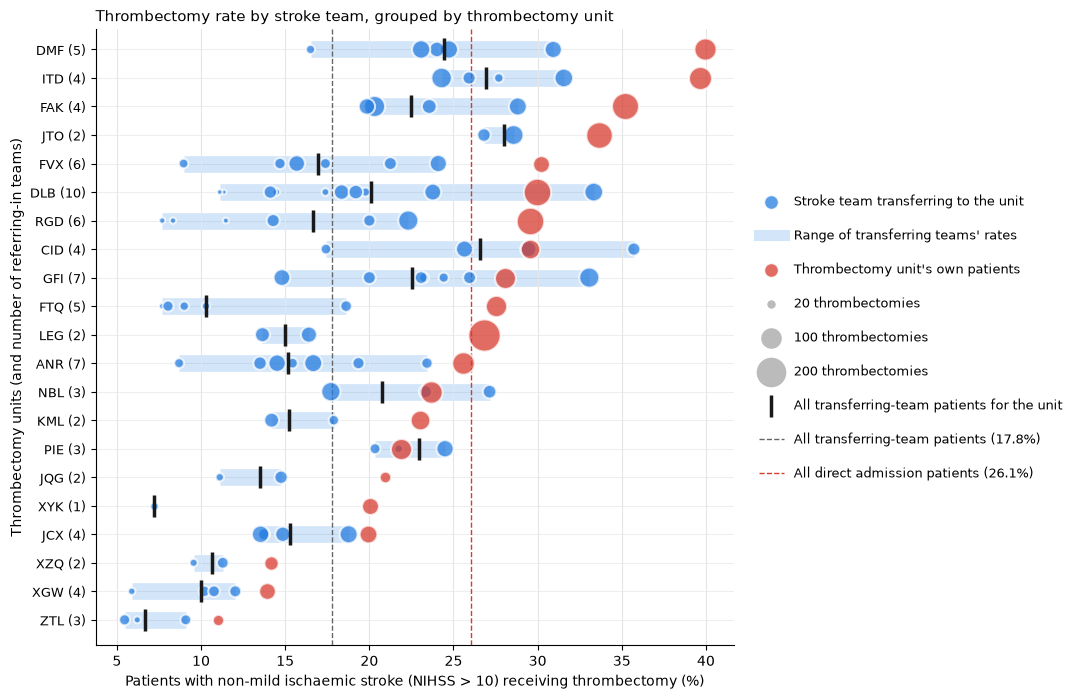

In [30]:
# Dot plot: one row per thrombectomy unit.
# Blue = stroke teams that transfer to the unit; red = the unit's own patients (first attended the unit).
# Circle area is proportional to the number of thrombectomies (procedures).
# Light blue band = range (lowest to highest) of the transferring teams' rates for each unit.
from matplotlib.lines import Line2D

team_rates['procedures'] = transfer_data.groupby('stroke_team')['thrombectomy'].sum()
unit_own = data_filtered[data_filtered['thrombectomy_centre'] == 1].groupby('stroke_team')[
    'thrombectomy'].agg(rate='mean', procedures='sum', n='size')

# Sort rows by the thrombectomy rate of each unit's own patients
order = unit_own.loc[unit_rates.index, 'rate'].sort_values().index
team_range = team_rates.groupby('unit')['rate'].agg(['min', 'max'])
blue, red, ink, grey = '#257de0', '#d63b2f', '#191919', '#666666'
size_per_procedure = 2.5  # marker area (points^2) per thrombectomy

fig, ax = plt.subplots(figsize=(11, 8))
for i, unit in enumerate(order):
    teams = team_rates[team_rates['unit'] == unit]
    ax.hlines(i, team_range.loc[unit, 'min'] * 100, team_range.loc[unit, 'max'] * 100,
              color=blue, alpha=0.2, linewidth=12, zorder=1)
    ax.scatter(teams['rate'] * 100, np.full(len(teams), i), s=teams['procedures'] * size_per_procedure,
               color=blue, alpha=0.75, edgecolor='white', linewidth=1.5, zorder=3)
    if unit in unit_own.index:
        ax.scatter(unit_own.loc[unit, 'rate'] * 100, i,
                   s=unit_own.loc[unit, 'procedures'] * size_per_procedure,
                   color=red, alpha=0.75, edgecolor='white', linewidth=1.5, zorder=3)
    ax.scatter(unit_rates.loc[unit, 'rate'] * 100, i, marker='|', s=250,
               color=ink, linewidth=2.5, zorder=4)

overall = transfer_data['thrombectomy'].mean() * 100
ax.axvline(overall, color=grey, linestyle='--', linewidth=1, zorder=1)

# All patients admitted directly to a thrombectomy unit (first attended any thrombectomy centre)
direct = data_filtered.loc[data_filtered['thrombectomy_centre'] == 1, 'thrombectomy'].mean() * 100
ax.axvline(direct, color=red, linestyle='--', linewidth=1, zorder=1)

ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{u} ({unit_rates.loc[u, 'teams']})" for u in order], fontsize=9)
ax.set_xlabel('Patients with non-mild ischaemic stroke (NIHSS > 10) receiving thrombectomy (%)')
ax.set_ylabel('Thrombectomy units (and number of referring-in teams)')
ax.set_ylim(-0.9, len(order) - 0.3)
ax.grid(axis='x', color='#e5e5e5', linewidth=0.8, zorder=0)
# Faint horizontal line along each thrombectomy unit's row
for row in range(len(order)):
    ax.axhline(row, color='#eeeeee', linewidth=0.8, zorder=0)
ax.spines[['top', 'right']].set_visible(False)

# Legend: colours, circle sizes (in procedures) and the unit marker
handles = [
    ax.scatter([], [], s=40 * size_per_procedure, color=blue, alpha=0.75, edgecolor='white',
               label='Stroke team transferring to the unit'),
    ax.scatter([], [], s=40 * size_per_procedure, color=red, alpha=0.75, edgecolor='white',
               label="Thrombectomy unit's own patients"),
]
handles.insert(1, Line2D([], [], color=blue, alpha=0.2, linewidth=8,
                         label="Range of transferring teams' rates"))
handles += [ax.scatter([], [], s=p * size_per_procedure, color='#bbbbbb', edgecolor='white',
                       label=f'{p} thrombectomies') for p in (20, 100, 200)]
handles.append(ax.scatter([], [], marker='|', s=250, color=ink, linewidth=2.5,
                          label='All transferring-team patients for the unit'))
handles.append(Line2D([], [], color=grey, linestyle='--', linewidth=1,
                      label=f'All transferring-team patients ({overall:.1f}%)'))
handles.append(Line2D([], [], color=red, linestyle='--', linewidth=1,
                      label=f'All direct admission patients ({direct:.1f}%)'))
ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False,
          fontsize=9, labelspacing=1.6, borderpad=1)

ax.set_title('Thrombectomy rate by stroke team, grouped by thrombectomy unit', loc='left', fontsize=11)
fig.subplots_adjust(left=0.14, right=0.72)  # leave room for the legend on the right
plt.savefig('./output/mt_transfer_by_team_and_unit.jpg', dpi=300, bbox_inches='tight')
plt.show()

**Results:** Transferring teams cluster around their unit's rate (black tick), which ranges from 6.7% to 28.0% across units. Rows are sorted by the rate for the unit's own patients (11.0% to 39.9%); the transferring teams' rate broadly rises with it, but not strictly in order. Teams transferring to the same unit still differ, but by less than teams overall.

Overall, 26.1% of patients admitted directly to a thrombectomy unit received thrombectomy (n = 8,851), compared with 17.8% of patients of transferring teams. Each unit's own patients (red) are more likely to receive thrombectomy than patients of its transferring teams (higher in 20 of 21 units, by a median of 7.8 percentage points; the units' own rates range from 11.0% to 39.9%). A unit's own rate also tracks its transferring teams' rate closely (r = 0.78, Spearman 0.76, across 21 units): units that treat more of their own patients also accept more transfers. This suggests part of the unit effect reflects the unit's own threshold for thrombectomy, not only geography, although case mix of directly admitted patients may differ.

The rates of individual transferring teams vary within each unit (blue band), with a median range of 8.1 percentage points between a unit's lowest and highest team. Ranges are wider where more teams share a unit: all eight units with a range over 10 points have 4 to 10 teams, the widest being DLB (10 teams, 11.1% to 33.3%). XYK has a single transferring team, so it has no range. In 16 of 21 units, the unit's own rate is higher than that of every one of its transferring teams.

### Referring teams' rates and the thrombectomy unit's own rate

**What this cell does:** For each referring stroke team (one point each, 86 teams), plots the thrombectomy rate for the own patients of the thrombectomy unit the team transfers to (x-axis) against the team's own thrombectomy rate (y-axis). Teams transferring to the same unit share an x value. Circle area is proportional to the team's number of patients. Reports Pearson and Spearman correlations and fits an unweighted linear regression across all teams, shown with its 95% confidence band, alongside the line of equality (dashed). Uses `team_rates` and `unit_own` from the cells above. The figure is saved to `./output/mt_unit_own_vs_transfer_in.jpg`.

Referring stroke teams: 86; thrombectomy units: 21
Pearson r = 0.57 (p = 1e-08); Spearman rho = 0.52 (p = 3e-07)
Slope: 0.58 (95% CI 0.40 to 0.76); R2 = 0.32


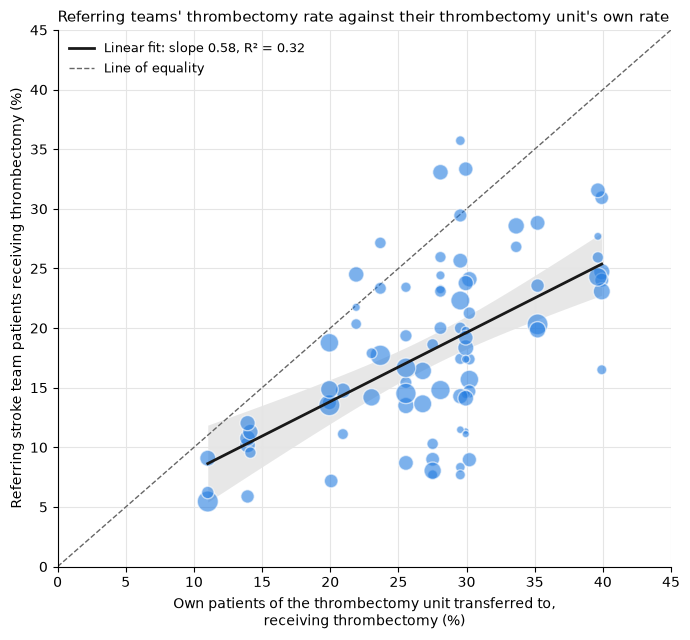

In [32]:
from scipy import stats
import statsmodels.api as sm

# One point per referring stroke team: rate for the own patients of the thrombectomy unit the team
# transfers to (x) against the team's own thrombectomy rate (y)
team_compare = team_rates[['unit', 'rate', 'n']].join(
    unit_own['rate'].rename('unit_own_rate'), on='unit')
x, y = team_compare['unit_own_rate'] * 100, team_compare['rate'] * 100

r, p = stats.pearsonr(x, y)
rho, p_rho = stats.spearmanr(x, y)
fit = sm.OLS(y, sm.add_constant(x)).fit()
slope, (slope_lo, slope_hi) = fit.params.iloc[1], fit.conf_int().iloc[1]
print(f"Referring stroke teams: {len(team_compare)}; thrombectomy units: {team_compare['unit'].nunique()}")
print(f"Pearson r = {r:.2f} (p = {p:.1g}); Spearman rho = {rho:.2f} (p = {p_rho:.1g})")
print(f"Slope: {slope:.2f} (95% CI {slope_lo:.2f} to {slope_hi:.2f}); R2 = {fit.rsquared:.2f}")

# Plot: one circle per referring team (area proportional to its patients), linear fit across
# all teams with 95% CI, and line of equality
blue, ink, grey = '#257de0', '#191919', '#666666'
fig, ax = plt.subplots(figsize=(7, 6.5))
ax.scatter(x, y, s=team_compare['n'] / 2, color=blue, alpha=0.6,
           edgecolor='white', linewidth=1, zorder=3)

x_line = np.linspace(x.min(), x.max(), 100)
pred = fit.get_prediction(sm.add_constant(x_line)).summary_frame(alpha=0.05)
ax.fill_between(x_line, pred['mean_ci_lower'], pred['mean_ci_upper'], color=ink, alpha=0.1,
                linewidth=0, zorder=1)
ax.plot(x_line, pred['mean'], color=ink, linewidth=2, zorder=4,
        label=f'Linear fit: slope {slope:.2f}, R² = {fit.rsquared:.2f}')
lims = [0, 45]
ax.plot(lims, lims, color=grey, linestyle='--', linewidth=1, zorder=2, label='Line of equality')

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Own patients of the thrombectomy unit transferred to,\nreceiving thrombectomy (%)")
ax.set_ylabel('Referring stroke team patients receiving thrombectomy (%)')
ax.grid(color='#e5e5e5', linewidth=0.8, zorder=0)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='upper left', frameon=False, fontsize=9)
ax.set_title("Referring teams' thrombectomy rate against their thrombectomy unit's own rate",
             loc='left', fontsize=11)
plt.tight_layout()
plt.savefig('./output/mt_unit_own_vs_transfer_in.jpg', dpi=300)
plt.show()

**Results:** Across 86 referring stroke teams (21 thrombectomy units), a team's thrombectomy rate is correlated with the rate for its thrombectomy unit's own patients (Pearson r = 0.57, Spearman ρ = 0.52, both p < 0.001; R² = 0.32). The slope is 0.58 (95% CI 0.40 to 0.76): each 1 percentage point higher rate for the unit's own patients goes with about 0.6 points higher rate for its referring teams. Only 5 of the 86 teams lie above the line of equality, as referring teams' patients are generally less likely to receive thrombectomy than the unit's own patients.

Teams referring to the same unit still vary around the fitted line, so the unit's own rate explains about a third of the variation between individual teams. This suggests that part of the variation between teams in transfer for thrombectomy reflects the threshold for thrombectomy at the unit they transfer to, not only geography. The comparison is not adjusted for case mix, which may differ between directly admitted and referring-in patients.

## Conclusions

- **Thrombectomy use:** 20.5% of patients with ischaemic stroke and NIHSS > 10 received thrombectomy in 2024–2025: 26.1% of those who first attended a thrombectomy centre and 17.8% of those who first attended a non-thrombectomy centre.
- **Delay from transfer:** for patients who first attended a non-thrombectomy centre, arrival to thrombectomy took about 1.5 hours longer (median 221 versus 127 minutes). Thrombolysis made little difference to this time.
- **Who is treated after transfer:** patients treated after transfer are clinically similar to those treated directly (NIHSS, large vessel occlusion, comorbidities). The main differences are in timings, ethnicity, prior disability, perfusion imaging and thrombolysis, and crude outcomes are similar.
- **Variation between centres:** transfer rates for ischaemic stroke with NIHSS > 10 vary about 7-fold between non-thrombectomy centres (5.5% to 37.8%, excluding one centre with probable under-recording). Variation in thrombolysis explains very little of this (about 5–9% of the between-centre variance).
- **How many, not which:** given the same patients, teams differ about 3-fold in the odds of thrombectomy (11.3% versus 24.5% at the 10th and 90th centile teams), but weigh patient characteristics very similarly. Higher-rate teams do not extend thrombectomy to more marginal patients.
- **Role of the thrombectomy unit:** teams cluster around the rate of the thrombectomy unit they transfer to, and unit-level rates vary from 6.7% to 28.0%. A unit's rate for its own patients is higher than for its referring teams' patients in 20 of 21 units, and tracks it closely (r = 0.78 across units; R² = 0.32 across 86 individual teams). Part of the variation between teams may therefore reflect the threshold for thrombectomy at the receiving unit, as well as geography and the teams' own referral practice.

**Caveats:** these are observational, mostly unadjusted comparisons. The completed thrombectomy (not referral) is the outcome, imaging data are incomplete, and the XGBoost hyperparameters were tuned on an earlier version of the data file (set `retune_model = True` to re-tune).